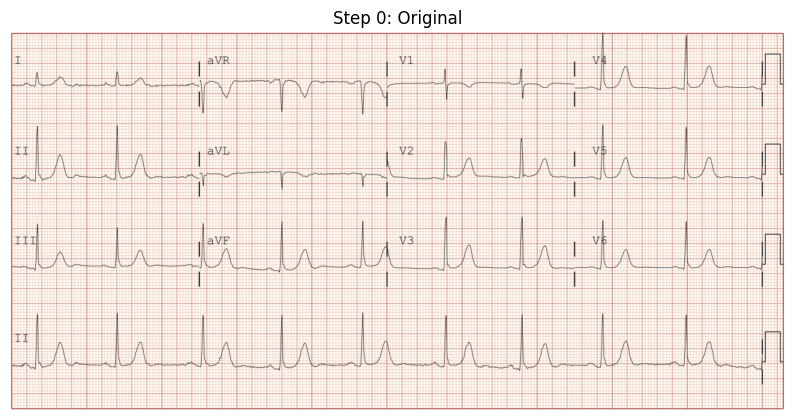

In [ ]:
import os, json, math
from dataclasses import dataclass
import numpy as np
import cv2
import matplotlib.pyplot as plt

ROOT_PATH = "../../data/raw/"
# IMG_PATH = os.path.join(ROOT_PATH, "1_reduced_EF/A2024542504.jpg")
# IMG_PATH = os.path.join(ROOT_PATH, "0_normal_EF/B2024544083.jpg")
# IMG_PATH = os.path.join(ROOT_PATH, "mitral_images/A2025563515.png")
IMG_PATH = os.path.join(ROOT_PATH, "/mnt/c/Documents/Kuliah/MLCV/ecg_digitization/experiments/ml_overlap_correction/data_gen/generated/crops_check/pages/0_rh3.png")
assert os.path.exists(IMG_PATH)

def imshow(img, title="", cmap=None, max_size=1200):
    disp = img.copy()
    if disp.ndim == 2:
        h, w = disp.shape
    else:
        h, w = disp.shape[:2]
    scale = min(1.0, max_size / max(h, w))
    if scale < 1.0:
        disp = cv2.resize(disp, (int(w*scale), int(h*scale)), interpolation=cv2.INTER_AREA)
    plt.figure(figsize=(10, 6))
    if disp.ndim == 2:
        plt.imshow(disp, cmap=cmap or "gray", vmin=0, vmax=255)
    else:
        plt.imshow(cv2.cvtColor(disp, cv2.COLOR_BGR2RGB))
    plt.title(title)
    plt.axis("off")
    plt.show()

def overlay_lines(img_bgr, xs=None, ys=None, title=""):
    out = img_bgr.copy()
    h, w = out.shape[:2]
    if ys is not None:
        for y in ys:
            cv2.line(out, (0, int(y)), (w-1, int(y)), (0, 255, 0), 2, cv2.LINE_AA)
    if xs is not None:
        for x in xs:
            cv2.line(out, (int(x), 0), (int(x), h-1), (255, 0, 0), 2, cv2.LINE_AA)
    imshow(out, title)

def overlay_boxes(img_bgr, boxes, title=""):
    out = img_bgr.copy()
    for (x0,y0,x1,y1) in boxes:
        cv2.rectangle(out, (int(x0),int(y0)), (int(x1),int(y1)), (0,255,0), 2)
    imshow(out, title)

def hist_plot(values, title="", bins=120):
    plt.figure(figsize=(8,4))
    plt.hist(values.ravel(), bins=bins)
    plt.title(title)
    plt.xlabel("value")
    plt.ylabel("count")
    plt.show()

def detect_border_red_lines(mask_red, height, width):
    num, labels, stats, _ = cv2.connectedComponentsWithStats(mask_red, connectivity=8)
    border_mask = np.zeros_like(mask_red)
    max_thickness = max(3, int(0.012 * min(height, width)))
    min_hline_len = int(0.35 * width)
    min_vline_len = int(0.35 * height)
    border_band = max(2, int(0.01 * min(height, width)))

    for component in range(1, num):
        x, y, w, h, _ = stats[component]
        touches_border = (
            x <= border_band or y <= border_band or
            (x + w) >= (width - border_band) or
            (y + h) >= (height - border_band)
        )
        if not touches_border:
            continue
        thin_horizontal = h <= max_thickness and w >= min_hline_len
        thin_vertical = w <= max_thickness and h >= min_vline_len
        if thin_horizontal or thin_vertical:
            border_mask[labels == component] = 255
    return border_mask

P = {
    "preprocess_mode": "current_then_hybrid",
    "mask_method": "red_excess",
    "lab_a_thresh": 120,
    "use_otsu_for_red_excess": True,
    "red_excess_manual_thr": 12,
    "binarize": "otsu",
    "fixed_gray_thr": 100,
    "gray_thr_bright": 70,
    "dark_thresh": 121,
    "gray_thresh": 151,
    "spread_thresh": 38,
    "open_k": 1,
    "baseline_smooth_ksize": 61,
    "baseline_num_peaks": 4,
    "baseline_min_sep_ratio": 0.10,
    "sep_vclose_h": 65,
    "sep_vopen_ratio": 0.18,
    "sep_min_height_ratio": 0.10,
    "sep_max_width_px": 50,
    "sep_min_aspect": 4.0,
    "sep_cluster_tol_px": 24,
    "sep_min_cluster_members": 2,
    "sep_border_exclude_ratio": 0.03,
    "num_cols": 4,
    "crop_halfspan_ratio": 0.70,
    "rhythm_crop_extra_ratio": 0.08,
    "lr_pad_ratio": 0.015,
    "left_margin_ratio": 0.04,
    "right_margin_ratio": 0.02,
    "dilate_k": 3,
    "top_cc_enable": True,
    "top_cc_y_thresh_px": 45,
    "top_cc_y_anchor_offset_px": 3,
    "top_cc_min_width_px": 25,
    "top_cc_min_coverage_ratio": 0.25,
    "rhythm_bottom_cc_enable": True,
    "rhythm_bottom_cc_y_thresh_px": 15,
    "iterative_recovery_enable": True,
    "iterative_recovery_initial_halfspan_ratio": 0.70,
    "iterative_recovery_max_iters": 10,
    "iterative_recovery_target_span_ratio": 0.95,
    "iterative_recovery_step_ratio": 0.06,
    "iterative_recovery_soft_step_ratio": 0.03,
    "interp_dt_ms": 2.0,
    "time_seconds_total": 10.0,
    "voltage_time_ratio_mV_per_ms": 0.0025,
    "overlap_ratio_threshold": 0.03,
    "rhythm_overlap_ratio_threshold": 0.008,
    "overlap_vertical_close_h": 7,
    "overlap_column_count_threshold": 3,
    "mask_static_lead_names": False,
}


img = cv2.imread(IMG_PATH, cv2.IMREAD_COLOR)
H, W = img.shape[:2]
imshow(img, "Step 0: Original")

# Step 0.1: mask static lead name labels with white rectangles so they are
# never picked up as ink during preprocessing or trace extraction.
# Coordinates are (y_start, y_end, x_start, x_end) for each label box.
lead_label_positions = [
    (99,  133, 17,   40),
    (455, 487, 20,   71),
    (805, 840, 24,   99),
    (96,  133, 774,  865),
    (451, 485, 770,  860),
    (795, 840, 772,  863),
    (96,  133, 1523, 1584),
    (455, 487, 1524, 1588),
    (805, 844, 1526, 1590),
    (96,  130, 2289, 2346),
    (455, 487, 2289, 2346),
    (807, 839, 2289, 2348),
]

def mask_static_lead_names(image):
    cleaned = image.copy()
    for (yst, yen, xst, xen) in lead_label_positions:
        cv2.rectangle(cleaned, (xst, yst), (xen, yen), (255, 255, 255), -1)
    return cleaned

if P["mask_static_lead_names"]:
    img = mask_static_lead_names(img)
    imshow(img, "Step 0.1: Lead-label masked input")

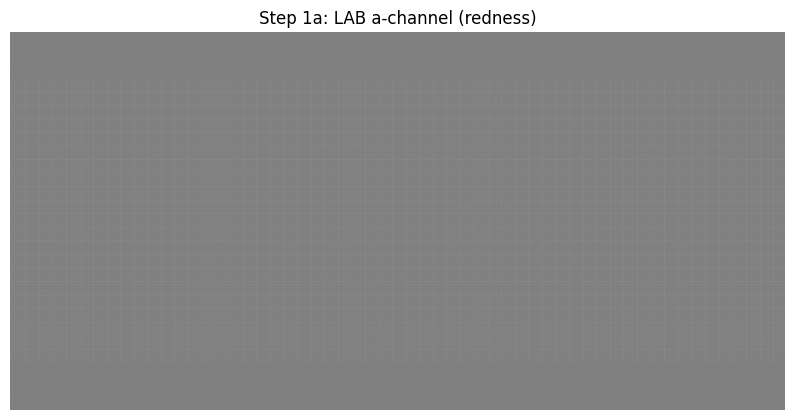

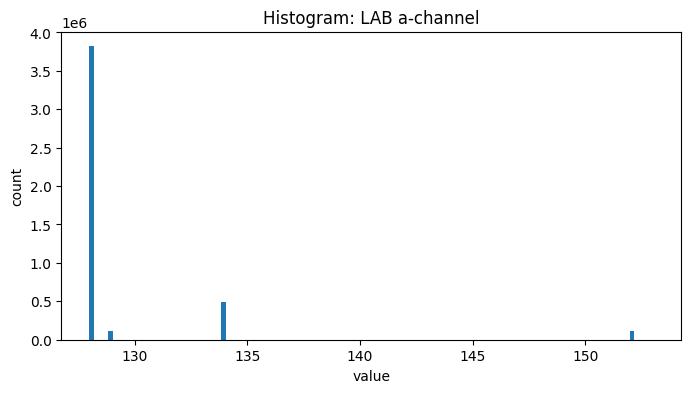

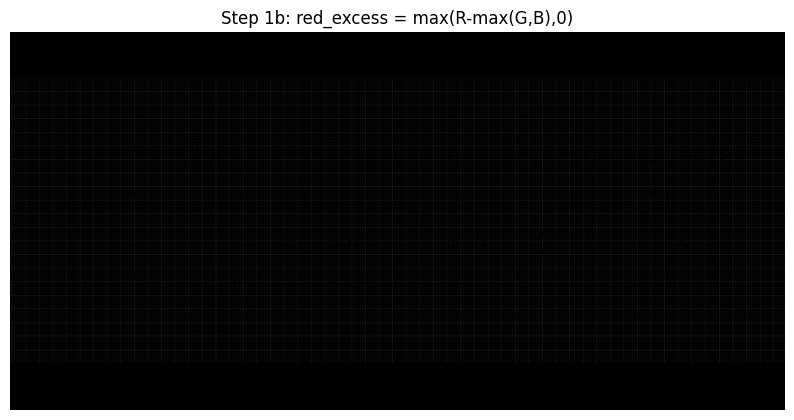

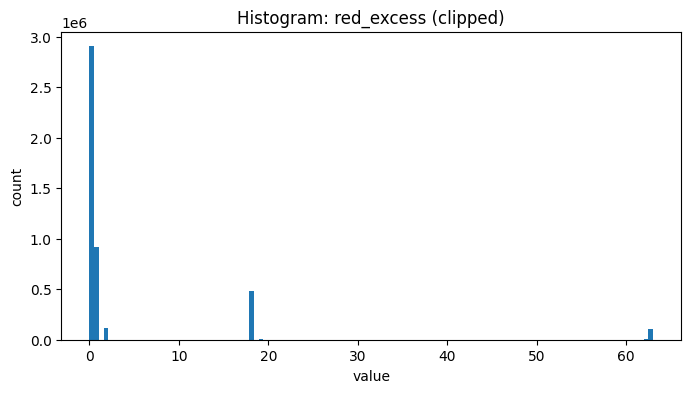

Chosen red_excess threshold: 32


In [3]:
# -----------------------------
# Step 1: build a "redness" score two ways
# -----------------------------

# LAB 'a' channel
lab = cv2.cvtColor(img, cv2.COLOR_BGR2LAB)
L, A, B = cv2.split(lab)
imshow(A, "Step 1a: LAB a-channel (redness)", cmap="gray")
hist_plot(A, "Histogram: LAB a-channel")

# "red excess" score: R - max(G,B)
b,g,r = cv2.split(img)
red_excess = r.astype(np.int16) - np.maximum(g, b).astype(np.int16)
red_excess_clip = np.clip(red_excess, 0, 255).astype(np.uint8)
imshow(red_excess_clip, "Step 1b: red_excess = max(R-max(G,B),0)", cmap="gray")
hist_plot(red_excess_clip, "Histogram: red_excess (clipped)")

if P["use_otsu_for_red_excess"]:
    thr_re, _ = cv2.threshold(red_excess_clip, 0, 255, cv2.THRESH_BINARY + cv2.THRESH_OTSU)
    thr_re = int(thr_re)
else:
    thr_re = int(P["red_excess_manual_thr"])
print("Chosen red_excess threshold:", thr_re)

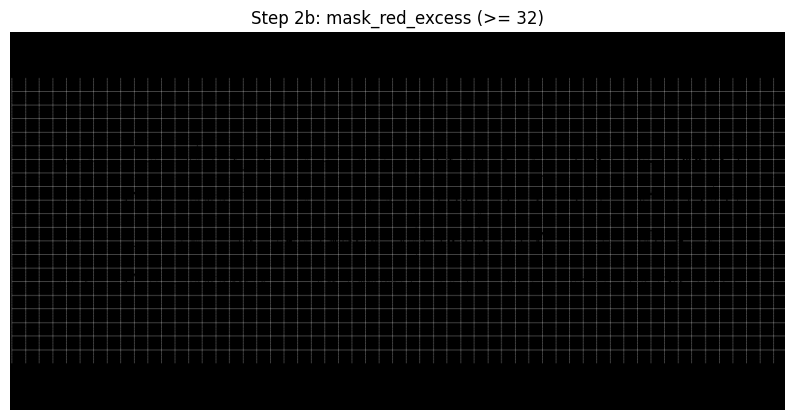

Auto gray_thr_bright: 95


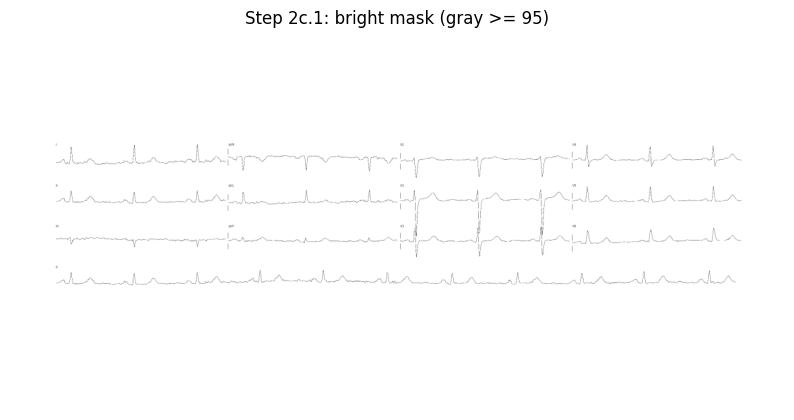

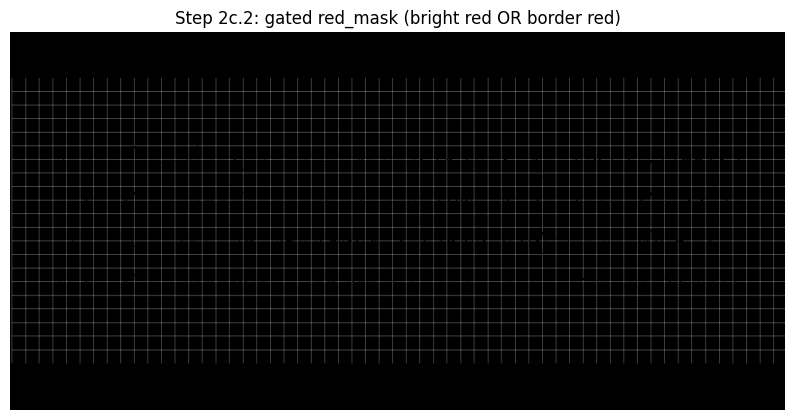

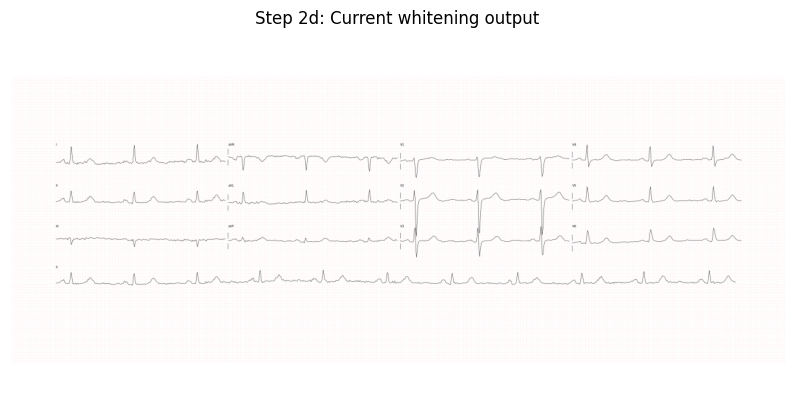

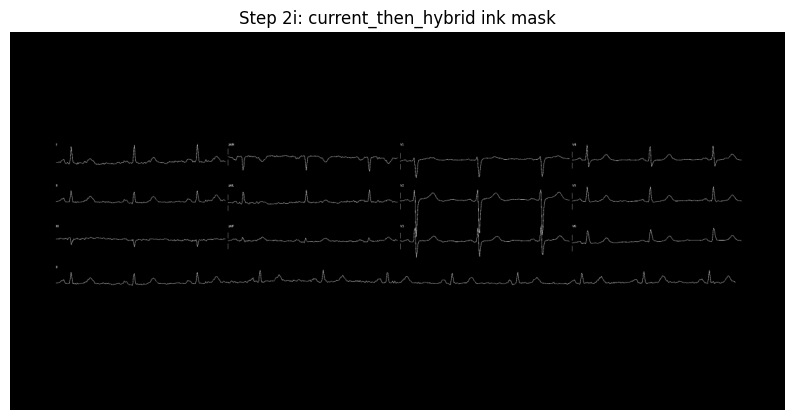

In [4]:
# -----------------------------
# Step 2: staged current -> dark_hybrid preprocessing
# -----------------------------

mask_lab = (A >= P["lab_a_thresh"]).astype(np.uint8) * 255
mask_re  = (red_excess_clip >= thr_re).astype(np.uint8) * 255

if P["mask_method"] == "lab_a":
    imshow(mask_lab, f"Step 2a: mask_lab (A >= {P['lab_a_thresh']})", cmap="gray")
    red_mask_raw = mask_lab
elif P["mask_method"] == "red_excess":
    imshow(mask_re, f"Step 2b: mask_red_excess (>= {thr_re})", cmap="gray")
    red_mask_raw = mask_re
else:
    imshow(mask_lab, f"Step 2a: mask_lab (A >= {P['lab_a_thresh']})", cmap="gray")
    imshow(mask_re, f"Step 2b: mask_red_excess (>= {thr_re})", cmap="gray")
    red_mask_raw = cv2.bitwise_or(mask_lab, mask_re)

gray0 = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)
vals = gray0[red_mask_raw > 0]
if vals.size > 0:
    thr = int(np.clip(np.percentile(vals, 0.25), 60, 130))
else:
    thr = int(P["gray_thr_bright"])

print("Auto gray_thr_bright:", thr)

bright = (gray0 >= thr).astype(np.uint8) * 255
border_red = detect_border_red_lines(red_mask_raw, H, W)
red_mask = cv2.bitwise_or(cv2.bitwise_and(red_mask_raw, bright), border_red)

imshow(bright, f"Step 2c.1: bright mask (gray >= {thr})", cmap="gray")
imshow(red_mask, "Step 2c.2: gated red_mask (bright red OR border red)", cmap="gray")

img_current = img.copy()
img_current[red_mask > 0] = (255, 255, 255)
imshow(img_current, "Step 2d: Current whitening output")

stage_gray = cv2.cvtColor(img_current, cv2.COLOR_BGR2GRAY)
max_channel = img_current.max(axis=2).astype(np.uint8)
min_channel = img_current.min(axis=2).astype(np.uint8)
channel_spread = (max_channel - min_channel).astype(np.uint8)

strong_black = max_channel <= P["dark_thresh"]
neutral_dark = (stage_gray <= P["gray_thresh"]) & (channel_spread <= P["spread_thresh"])
ink = (strong_black | neutral_dark).astype(np.uint8) * 255

if P["open_k"] > 1:
    kernel = cv2.getStructuringElement(cv2.MORPH_RECT, (int(P["open_k"]), int(P["open_k"])))
    ink = cv2.morphologyEx(ink, cv2.MORPH_OPEN, kernel, iterations=1)

img_whiten = np.full_like(img, 255)
img_whiten[ink > 0] = (0, 0, 0)

# imshow(stage_gray, "Step 2e: grayscale after current whitening", cmap="gray")
# imshow(max_channel, "Step 2f: max_channel after current whitening", cmap="gray")
# imshow(channel_spread, "Step 2g: channel_spread after current whitening", cmap="gray")
# imshow(img_whiten, "Step 2h: current_then_hybrid filtered image")
imshow(ink, "Step 2i: current_then_hybrid ink mask", cmap="gray")


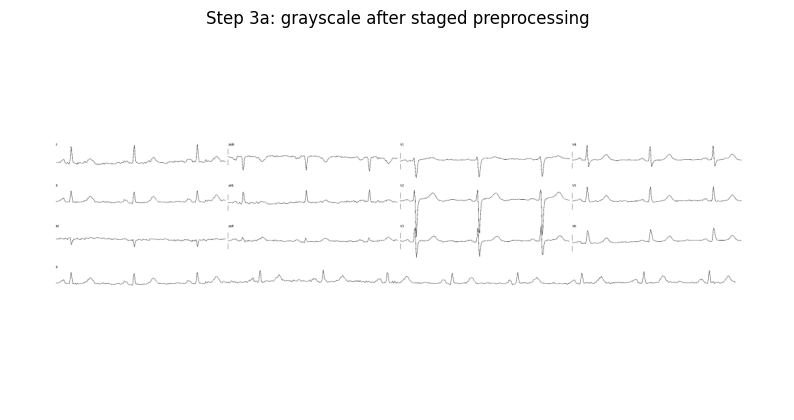

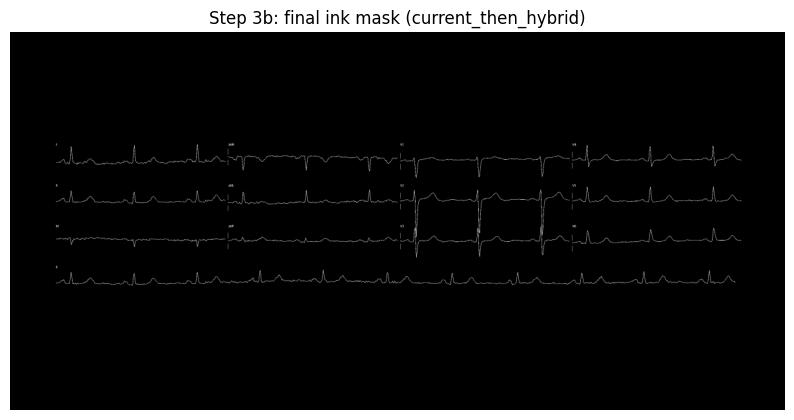

In [5]:
# -----------------------------
# Step 3: inspect final ink mask used downstream
# -----------------------------
gray = cv2.cvtColor(img_whiten, cv2.COLOR_BGR2GRAY)
imshow(gray, "Step 3a: grayscale after staged preprocessing", cmap="gray")
imshow(ink, "Step 3b: final ink mask (current_then_hybrid)", cmap="gray")


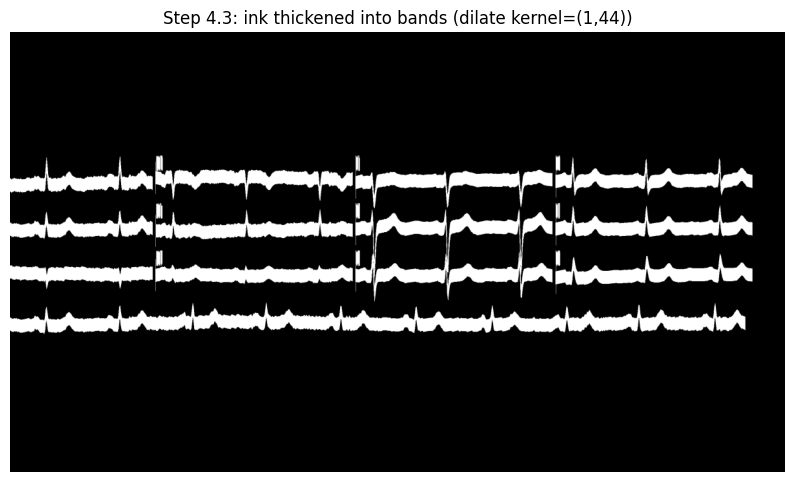

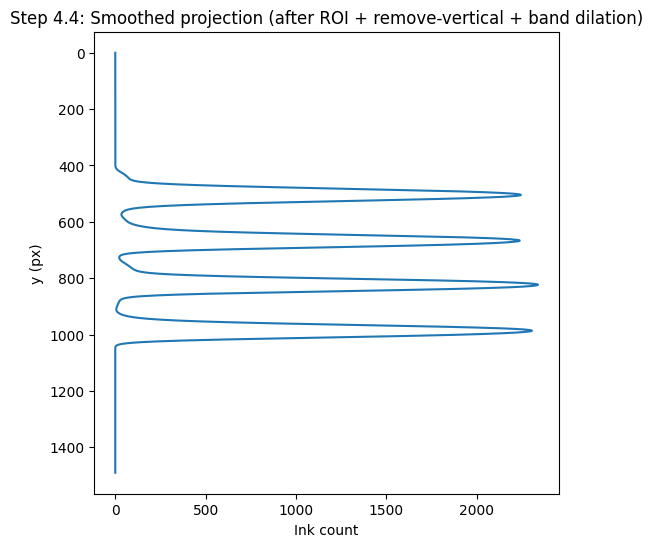

Baselines (robust projection): [171, 504, 823, 1119]


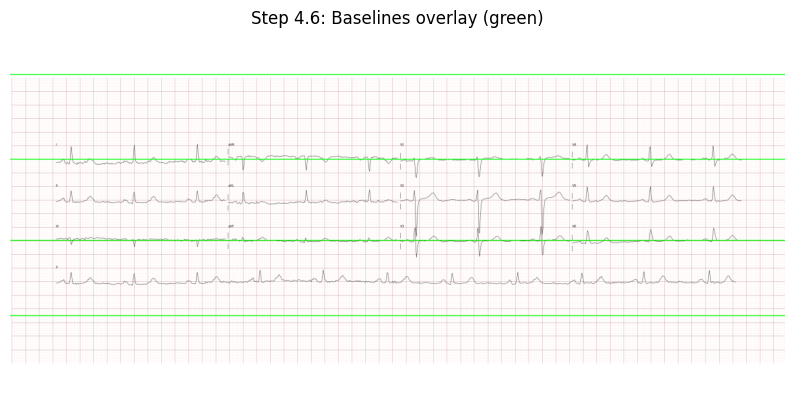

In [7]:
# -----------------------------
# Step 4: baselines via projection (robust)
# -----------------------------

# 4.1 Restrict ROI to avoid left lead labels and right calibration area
xL = int(0.12 * W)     # tune: 0.08–0.18
xR = int(0.98 * W)     # tune: 0.95–0.99
ink_roi = ink[:, xL:xR]
# imshow(ink_roi, f"Step 4.1: ink ROI for baseline projection (x={xL}:{xR})")

vk_h = max(25, int(0.20 * H))
vk = cv2.getStructuringElement(cv2.MORPH_RECT, (3, vk_h))
vertical_only = cv2.morphologyEx(ink_roi, cv2.MORPH_OPEN, vk, iterations=1)
# imshow(vertical_only, f"Step 4.2a: vertical-only (OPEN kernel=(3,{vk_h}))")

ink_novert = cv2.bitwise_and(ink_roi, cv2.bitwise_not(vertical_only))
# imshow(ink_novert, "Step 4.2b: ink ROI with vertical strokes removed")

band_h = max(9, int(0.03 * H))  # tune: 0.02–0.06 of H
band_k = cv2.getStructuringElement(cv2.MORPH_RECT, (1, band_h))
ink_band = cv2.dilate(ink_novert, band_k, iterations=1)
imshow(ink_band, f"Step 4.3: ink thickened into bands (dilate kernel=(1,{band_h}))")

proj = (ink_band > 0).sum(axis=1).astype(np.float32)

ks = int(P["baseline_smooth_ksize"])
if ks % 2 == 0:
    ks += 1
proj_s = cv2.GaussianBlur(proj.reshape(-1,1), (1, ks), 0).ravel()

plt.figure(figsize=(6,6))
plt.plot(proj_s, np.arange(len(proj_s)))
plt.gca().invert_yaxis()
plt.title("Step 4.4: Smoothed projection (after ROI + remove-vertical + band dilation)")
plt.xlabel("Ink count")
plt.ylabel("y (px)")
plt.show()

# 4.5 Peak picking: use LOCAL maxima candidates
def pick_peaks_local(y, top_k, min_sep):
    y = np.asarray(y)

    cand = np.where((y[1:-1] >= y[:-2]) & (y[1:-1] >= y[2:]))[0] + 1
    cand = cand[np.argsort(y[cand])[::-1]]

    peaks = []
    for idx in cand:
        if all(abs(idx - p) > min_sep for p in peaks):
            peaks.append(int(idx))
        if len(peaks) >= top_k:
            break
    return sorted(peaks)



K = P["baseline_num_peaks"]
min_sep = int(0.18 * H)  # IMPORTANT: try 0.15–0.25; 0.10 is often too small

y_min = int(0.05 * H)   # ignore top 5%
y_max = int(0.95 * H)   # ignore bottom 5%

proj_s2 = proj_s.copy()
proj_s2[:y_min] = -1e9
proj_s2[y_max:] = -1e9

baselines = pick_peaks_local(proj_s2, top_k=K, min_sep=min_sep)


print("Baselines (robust projection):", baselines)
overlay_lines(img, ys=baselines, title="Step 4.6: Baselines overlay (green)")


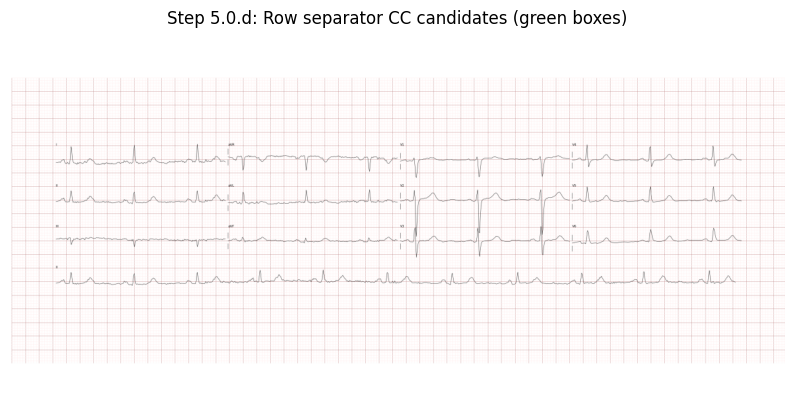

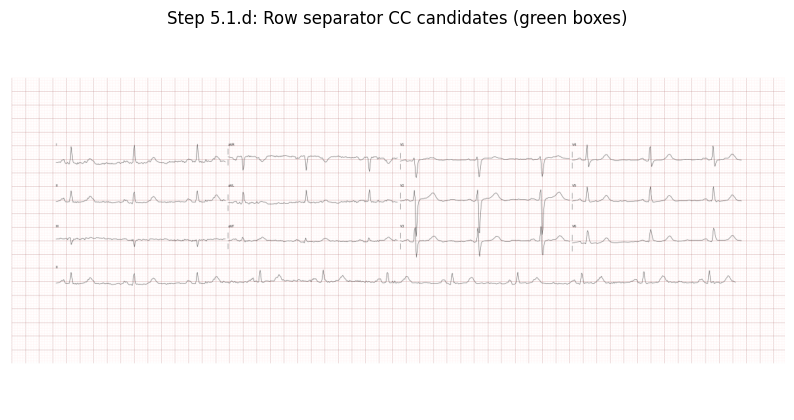

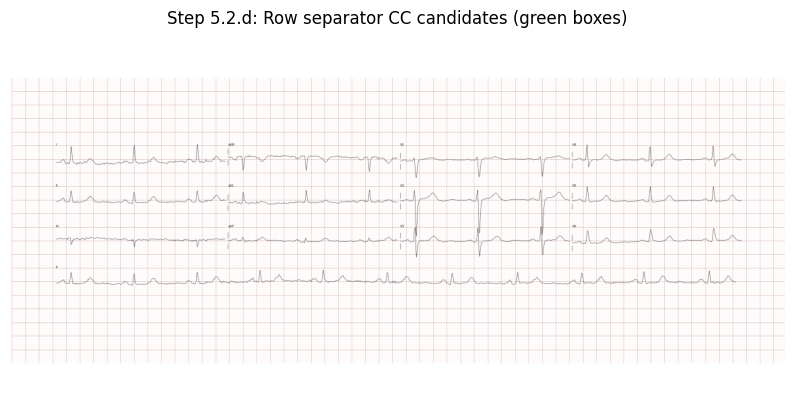

Per-row separator xs: [[], [], []]
Clusters: []
Chosen separators: []


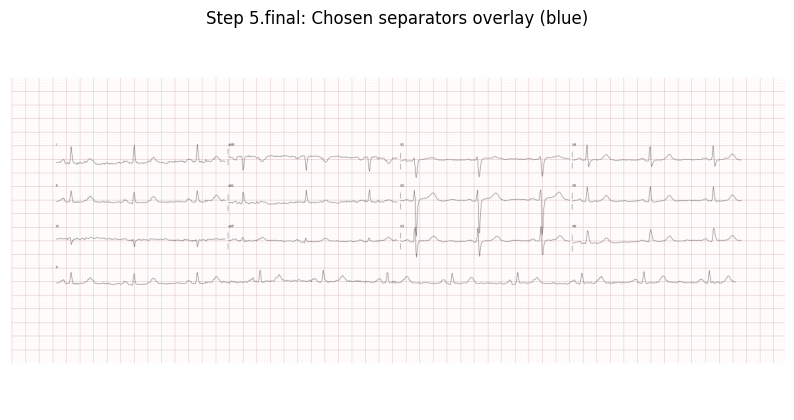

In [8]:
# -----------------------------
# Step 5: detect column separators row-wise + cluster
# -----------------------------
baselines_3 = baselines[:3]

vd = float(np.mean(np.diff(baselines_3))) if len(baselines_3) >= 2 else H/4
halfspan = int(P["crop_halfspan_ratio"] * vd)

def detect_seps_in_row(row_img, row_h):
    close_h = int(P["sep_vclose_h"])
    vk_close = cv2.getStructuringElement(cv2.MORPH_RECT, (3, max(5, close_h)))
    row_closed = cv2.morphologyEx(row_img, cv2.MORPH_CLOSE, vk_close, iterations=1)

    open_h = max(10, int(0.35 * row_h))   # tune 0.25–0.50
    vk_open = cv2.getStructuringElement(cv2.MORPH_RECT, (3, open_h))
    row_v = cv2.morphologyEx(row_closed, cv2.MORPH_OPEN, vk_open, iterations=1)
    return row_closed, row_v, open_h

per_row_x = []
all_boxes = []

for r_i, yb in enumerate(baselines_3):
    y0 = max(0, int(yb - halfspan))
    y1 = min(H, int(yb + halfspan))
    row = ink[y0:y1, :]

    row_closed, row_v, open_h = detect_seps_in_row(row, y1-y0)

    # imshow(row, f"Step 5.{r_i}.a: Row band ink [{y0}:{y1}]")
    # imshow(row_closed, f"Step 5.{r_i}.b: Row after vertical CLOSE (h={P['sep_vclose_h']})")
    # imshow(row_v, f"Step 5.{r_i}.c: Row after vertical OPEN (h={open_h})")

    num, lab_cc, st, cen = cv2.connectedComponentsWithStats(row_v, connectivity=8)
    baseline_local = int(yb - y0)
    xs = []
    boxes = []
    for i in range(1, num):
        x, y, w, h, area = st[i]
        cx, cy = cen[i]

        # IMPORTANT: use margin exclusion based on real layout, not tiny 3%
        if cx < 0.10*W or cx > 0.97*W:   # tune left=0.08–0.15, right=0.95–0.99
            continue
        if h < 0.20*(y1-y0):             # tune 0.15–0.35
            continue
        if w > 60:                       # separators can be thicker in scans
            continue
        if (h / max(w,1)) < 2.5:
            continue
        if not np.any(lab_cc[baseline_local, :] == i):
            continue

        xs.append(float(cx))
        boxes.append((x, y0+y, x+w, y0+y+h))

    per_row_x.append(xs)
    all_boxes += boxes

    overlay_boxes(img, boxes, f"Step 5.{r_i}.d: Row separator CC candidates (green boxes)")
    if xs:
        overlay_lines(img, xs=xs, title=f"Step 5.{r_i}.e: Row candidate separator x's (blue)")

print("Per-row separator xs:", per_row_x)

# cluster x across rows
all_x = []
row_id = []
for r_i, xs in enumerate(per_row_x):
    for x in xs:
        all_x.append(x)
        row_id.append(r_i)

all_x = np.array(all_x, dtype=np.float32)
row_id = np.array(row_id, dtype=np.int32)

clusters = []
for idx in np.argsort(all_x):
    x = float(all_x[idx]); r = int(row_id[idx])
    if not clusters:
        clusters.append({"xs":[x], "rows":set([r])})
    else:
        if abs(x - np.mean(clusters[-1]["xs"])) <= P["sep_cluster_tol_px"]:
            clusters[-1]["xs"].append(x); clusters[-1]["rows"].add(r)
        else:
            clusters.append({"xs":[x], "rows":set([r])})

cand = []
for cl in clusters:
    cand.append({"x": float(np.mean(cl["xs"])),
                 "n": len(cl["xs"]),
                 "row_count": len(cl["rows"])})
cand = sorted(cand, key=lambda d: (-d["row_count"], -d["n"], d["x"]))
print("Clusters:", cand[:10])

needed = P["num_cols"] - 1
sep_xs = sorted([d["x"] for d in cand if d["row_count"] >= 2][:needed])

print("Chosen separators:", sep_xs)
overlay_lines(img, xs=sep_xs, title="Step 5.final: Chosen separators overlay (blue)")


Fallback separators: [np.float64(837.75), np.float64(1554.5), np.float64(2271.25)]


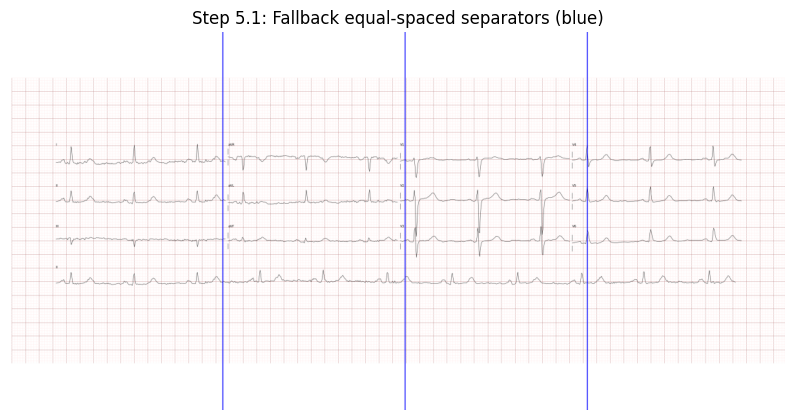

In [9]:
# -----------------------------
# Step 5.1: Fallback if separators not found (equal spacing)
# -----------------------------
if len(sep_xs) != (P["num_cols"] - 1):
    print("WARNING: separator detection failed or incomplete. Using equal-spacing fallback.")
    left = int(P["left_margin_ratio"] * W)
    right = int(W - P["right_margin_ratio"] * W)
    sep_xs = list(np.linspace(left, right, P["num_cols"] + 1)[1:-1])
    print("Fallback separators:", sep_xs)
    overlay_lines(img, xs=sep_xs, title="Step 5.1: Fallback equal-spaced separators (blue)")


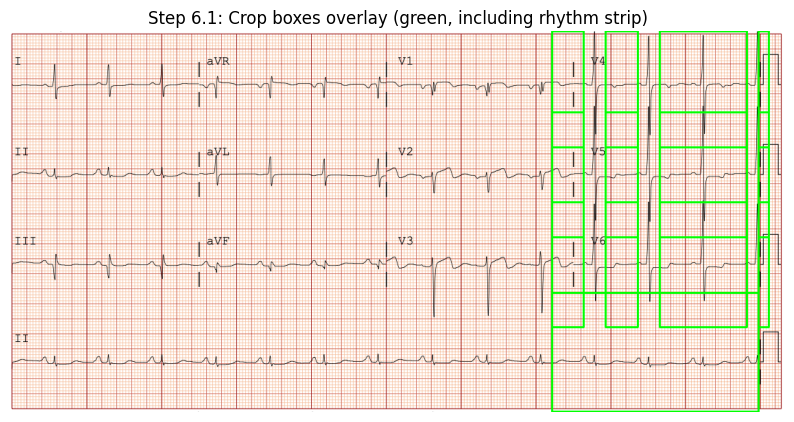

/tmp/ipykernel_10451/1487051916.py:57: UserWarning: Attempting to set identical low and high xlims makes transformation singular; automatically expanding.
  ax.imshow(crops[lead], cmap="gray", vmin=0, vmax=255)


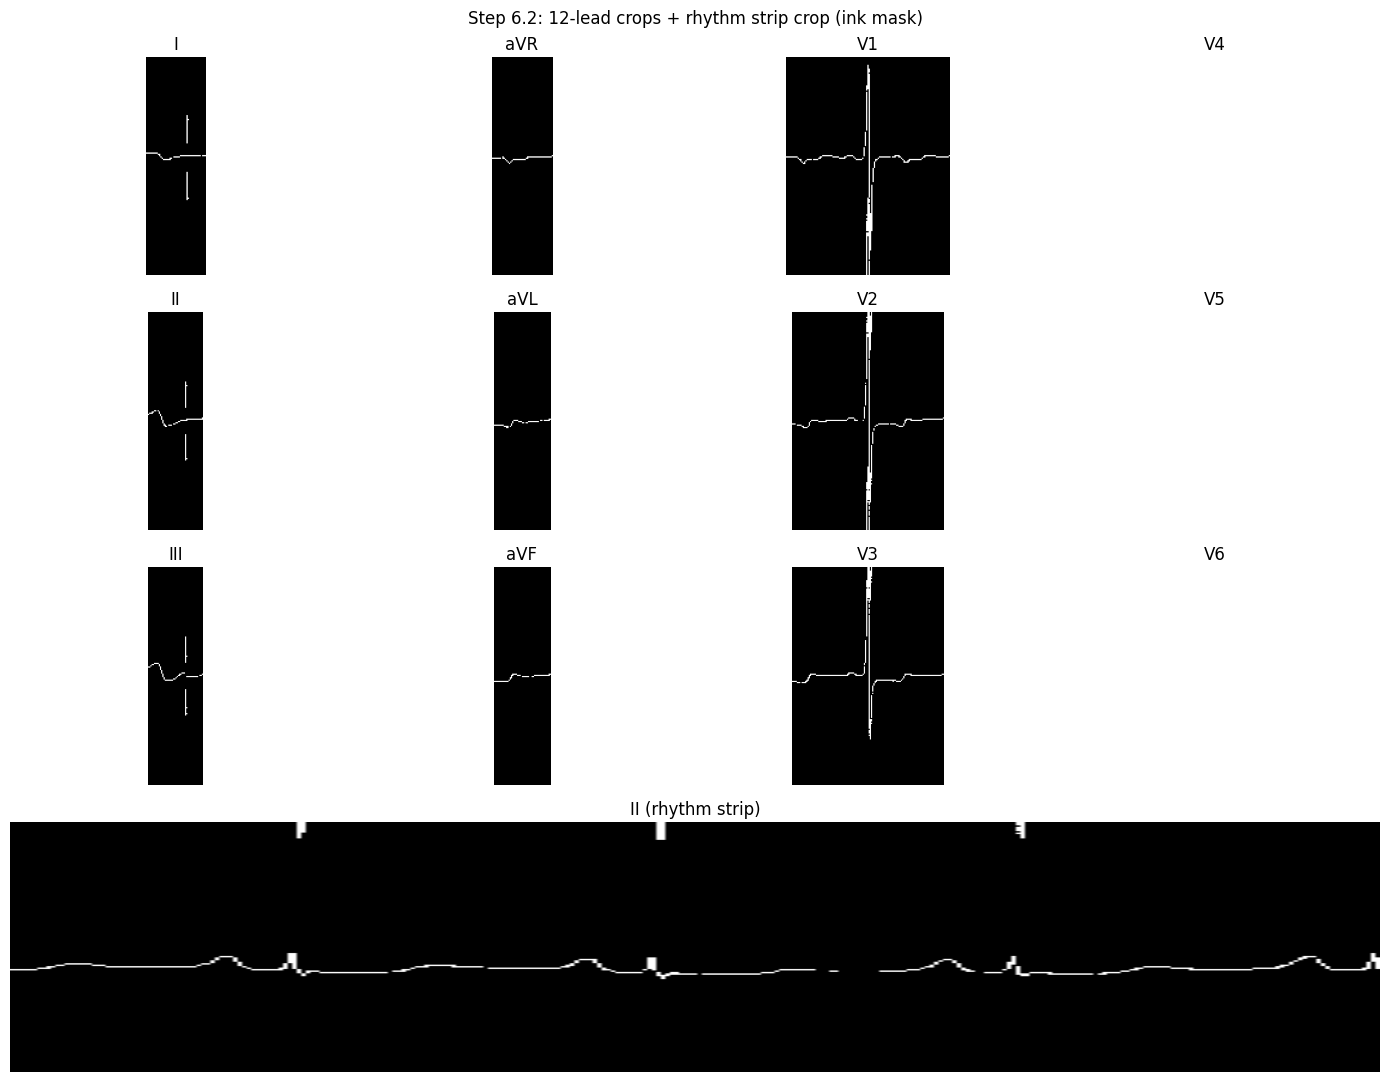

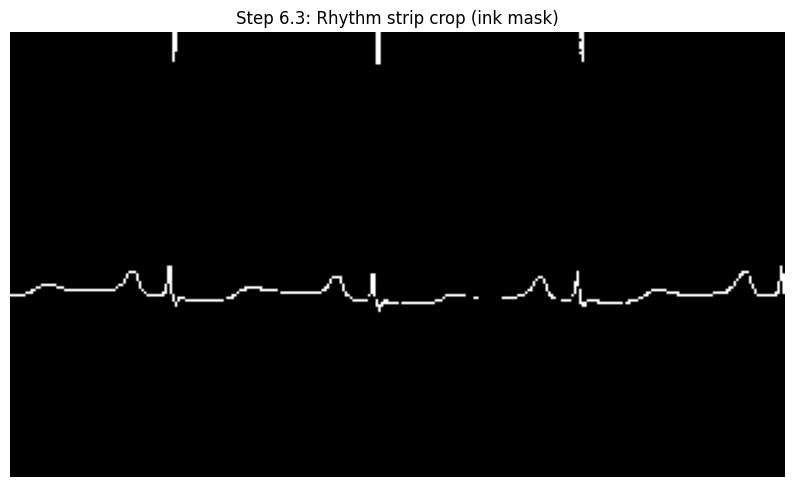

In [8]:
# -----------------------------
# Step 6: Crop 12-lead boxes (3 rows × 4 cols)
# -----------------------------
left = int(max(0, sep_xs[0] - (sep_xs[1] - sep_xs[0])))  # one column width to the left
right = int(W - P["right_margin_ratio"] * W)

bounds = [left] + [int(x) for x in sep_xs] + [right]
bounds = sorted(bounds)

lr_pad = int(P["lr_pad_ratio"] * W)

layout = [
    ["I","aVR","V1","V4"],
    ["II","aVL","V2","V5"],
    ["III","aVF","V3","V6"],
]

boxes = []
crops = {}
for r in range(3):
    yb = baselines_3[r]
    y0 = int(max(0, yb - halfspan))
    y1 = int(min(H-1, yb + halfspan))
    for c in range(4):
        x0 = int(max(0, bounds[c] + lr_pad))
        x1 = int(min(W-1, bounds[c+1] - lr_pad))
        boxes.append((x0, y0, x1, y1))
        crops[layout[r][c]] = ink[y0:y1, x0:x1].copy()

# Optional rhythm strip
rhythm = None
rhythm_box = None
rhythm_extra = int(P.get("rhythm_crop_extra_ratio", 0.08) * vd)
if len(baselines) >= 4:
    yb = baselines[3]
    y0 = int(max(0, yb - halfspan - rhythm_extra))
    y1 = int(min(H-1, yb + halfspan + rhythm_extra))
    rhythm_box = (int(left + lr_pad), y0, int(right - lr_pad), y1)
    rhythm = ink[y0:y1, left+lr_pad:right-lr_pad].copy()

boxes_viz = boxes + ([rhythm_box] if rhythm_box is not None else [])
overlay_boxes(img, boxes_viz, "Step 6.1: Crop boxes overlay (green, including rhythm strip)")

# show the 12 crops (+ rhythm strip when present)
if rhythm is not None:
    fig = plt.figure(figsize=(14, 11))
    gs = fig.add_gridspec(4, 4, height_ratios=[1, 1, 1, 1.15])
    axes = [[fig.add_subplot(gs[r, c]) for c in range(4)] for r in range(3)]
else:
    fig, axes = plt.subplots(3,4, figsize=(14,8))
for r in range(3):
    for c in range(4):
        lead = layout[r][c]
        ax = axes[r][c] if rhythm is not None else axes[r,c]
        ax.axis("off")
        ax.set_title(lead)
        ax.imshow(crops[lead], cmap="gray", vmin=0, vmax=255)
if rhythm is not None:
    ax_rhythm = fig.add_subplot(gs[3, :])
    ax_rhythm.axis("off")
    ax_rhythm.set_title("II (rhythm strip)")
    ax_rhythm.imshow(rhythm, cmap="gray", vmin=0, vmax=255, aspect="auto")
    plt.suptitle("Step 6.2: 12-lead crops + rhythm strip crop (ink mask)")
else:
    plt.suptitle("Step 6.2: 12-lead crops (ink mask)")
plt.tight_layout()
plt.show()

if rhythm is not None:
    imshow(rhythm, "Step 6.3: Rhythm strip crop (ink mask)")

In [9]:
# -----------------------------
# Step 7: Extract recovered lead crops + traces with notebook-local adaptive_70 logic
# -----------------------------
TOP_ROW_LEADS = {"I", "aVR", "V1", "V4"}
TOP_EDGE_PX = 2
BOTTOM_EDGE_PX = 2

@dataclass
class LeadResultLocal:
    lead: str
    crop_binary: np.ndarray
    crop_box: tuple
    connected_mask: np.ndarray
    processed_trace_view_bgr: np.ndarray
    y_trace: np.ndarray | None
    interpolation_mask: np.ndarray | None = None

def build_trace_from_mask_local(mask):
    if mask.size == 0:
        return None
    _, width = mask.shape
    y_med = np.full(width, np.nan, dtype=np.float32)
    for x_coord in range(width):
        ys = np.where(mask[:, x_coord] > 0)[0]
        if ys.size:
            y_med[x_coord] = np.median(ys)
    if np.isnan(y_med).all():
        return None
    return y_med

def _find_edge_index_local(proj, search_len, from_start):
    if proj.size == 0:
        return None
    if from_start:
        region = proj[:search_len]
        offset = 0
    else:
        region = proj[-search_len:]
        offset = proj.size - search_len
    if region.size == 0:
        return None
    peak = float(region.max(initial=0.0))
    if peak <= 0.0:
        return None
    thresh = max(0.12, 0.50 * peak)
    idxs = np.where(region >= thresh)[0]
    if idxs.size == 0:
        return None
    return int(offset + (idxs[0] if from_start else idxs[-1]))

def detect_red_frame_top_local(image_bgr):
    h, w = image_bgr.shape[:2]
    if h == 0 or w == 0:
        return None
    b, g, r = cv2.split(image_bgr)
    red_score = r.astype(np.int16) - np.maximum(g, b).astype(np.int16)
    red_mask = ((red_score >= 14) & (r >= 55)).astype(np.uint8) * 255
    horiz_kernel = cv2.getStructuringElement(cv2.MORPH_RECT, (max(21, int(0.08 * w)), 1))
    mask_h = cv2.morphologyEx(red_mask, cv2.MORPH_CLOSE, horiz_kernel)
    row_proj = (mask_h > 0).mean(axis=1).astype(np.float32)
    return _find_edge_index_local(row_proj, max(10, int(0.35 * h)), True)

def interpolate_short_gaps_local(trace, max_gap=24):
    out = trace.copy()
    valid = ~np.isnan(out)
    n = len(out)
    x_coord = 0
    while x_coord < n:
        if valid[x_coord]:
            x_coord += 1
            continue
        start = x_coord
        while x_coord < n and not valid[x_coord]:
            x_coord += 1
        end = x_coord
        gap = end - start
        left = start - 1
        right = end
        if gap <= max_gap and left >= 0 and right < n and valid[left] and valid[right]:
            out[start:end] = np.interp(
                np.arange(start, end, dtype=np.float32),
                np.array([left, right], dtype=np.float32),
                np.array([out[left], out[right]], dtype=np.float32),
            )
    return out


def interpolate_short_gaps_with_mask_local(trace, max_gap=24):
    if trace is None:
        return None, None
    out = trace.copy()
    filled = np.zeros(len(out), dtype=np.uint8)
    valid = ~np.isnan(out)
    n = len(out)
    x_coord = 0
    while x_coord < n:
        if valid[x_coord]:
            x_coord += 1
            continue
        start = x_coord
        while x_coord < n and not valid[x_coord]:
            x_coord += 1
        end = x_coord
        gap = end - start
        left = start - 1
        right = end
        if gap <= max_gap and left >= 0 and right < n and valid[left] and valid[right]:
            out[start:end] = np.interp(
                np.arange(start, end, dtype=np.float32),
                np.array([left, right], dtype=np.float32),
                np.array([out[left], out[right]], dtype=np.float32),
            )
            filled[start:end] = 1
    return out, filled


def interpolate_top_occluded_nan_gaps_local(trace, y_thresh, crop_height, max_gap):
    if trace is None or crop_height <= 0 or y_thresh <= 0:
        return trace
    out = trace.copy()
    band_margin = max(10.0, 0.08 * crop_height)
    valid = ~np.isnan(out)
    n = len(out)
    x_coord = 0
    while x_coord < n:
        if valid[x_coord]:
            x_coord += 1
            continue
        start = x_coord
        while x_coord < n and not valid[x_coord]:
            x_coord += 1
        end = x_coord
        gap = end - start
        left = start - 1
        right = end
        if gap > max_gap or left < 0 or right >= n or not valid[left] or not valid[right]:
            continue
        endpoints_near_top = (float(out[left]) <= y_thresh + band_margin) or (float(out[right]) <= y_thresh + band_margin)
        if not endpoints_near_top:
            continue
        out[start:end] = np.interp(
            np.arange(start, end, dtype=np.float32),
            np.array([left, right], dtype=np.float32),
            np.array([out[left], out[right]], dtype=np.float32),
        )
    return out


def interpolate_top_occluded_nan_gaps_with_mask_local(trace, y_thresh, crop_height, max_gap):
    if trace is None or crop_height <= 0 or y_thresh <= 0:
        return trace, None if trace is None else np.zeros(len(trace), dtype=np.uint8)
    out = trace.copy()
    filled = np.zeros(len(out), dtype=np.uint8)
    band_margin = max(10.0, 0.08 * crop_height)
    valid = ~np.isnan(out)
    n = len(out)
    x_coord = 0
    while x_coord < n:
        if valid[x_coord]:
            x_coord += 1
            continue
        start = x_coord
        while x_coord < n and not valid[x_coord]:
            x_coord += 1
        end = x_coord
        gap = end - start
        left = start - 1
        right = end
        if gap > max_gap or left < 0 or right >= n or not valid[left] or not valid[right]:
            continue
        endpoints_near_top = (float(out[left]) <= y_thresh + band_margin) or (float(out[right]) <= y_thresh + band_margin)
        if not endpoints_near_top:
            continue
        out[start:end] = np.interp(
            np.arange(start, end, dtype=np.float32),
            np.array([left, right], dtype=np.float32),
            np.array([out[left], out[right]], dtype=np.float32),
        )
        filled[start:end] = 1
    return out, filled


def interpolate_bottom_occluded_nan_gaps_local(trace, crop_height, max_gap):
    if trace is None or crop_height <= 0:
        return trace
    out = trace.copy()
    band_margin = max(10.0, 0.08 * crop_height)
    valid = ~np.isnan(out)
    n = len(out)
    x_coord = 0
    while x_coord < n:
        if valid[x_coord]:
            x_coord += 1
            continue
        start = x_coord
        while x_coord < n and not valid[x_coord]:
            x_coord += 1
        end = x_coord
        gap = end - start
        left = start - 1
        right = end
        if gap > max_gap or left < 0 or right >= n or not valid[left] or not valid[right]:
            continue
        bottom_band_y = (crop_height - 1) - band_margin
        endpoints_near_bottom = (float(out[left]) >= bottom_band_y) or (float(out[right]) >= bottom_band_y)
        if not endpoints_near_bottom:
            continue
        out[start:end] = np.interp(
            np.arange(start, end, dtype=np.float32),
            np.array([left, right], dtype=np.float32),
            np.array([out[left], out[right]], dtype=np.float32),
        )
    return out


def interpolate_bottom_occluded_nan_gaps_with_mask_local(trace, crop_height, max_gap):
    if trace is None or crop_height <= 0:
        return trace, None if trace is None else np.zeros(len(trace), dtype=np.uint8)
    out = trace.copy()
    filled = np.zeros(len(out), dtype=np.uint8)
    band_margin = max(10.0, 0.08 * crop_height)
    valid = ~np.isnan(out)
    n = len(out)
    x_coord = 0
    while x_coord < n:
        if valid[x_coord]:
            x_coord += 1
            continue
        start = x_coord
        while x_coord < n and not valid[x_coord]:
            x_coord += 1
        end = x_coord
        gap = end - start
        left = start - 1
        right = end
        if gap > max_gap or left < 0 or right >= n or not valid[left] or not valid[right]:
            continue
        bottom_band_y = (crop_height - 1) - band_margin
        endpoints_near_bottom = (float(out[left]) >= bottom_band_y) or (float(out[right]) >= bottom_band_y)
        if not endpoints_near_bottom:
            continue
        out[start:end] = np.interp(
            np.arange(start, end, dtype=np.float32),
            np.array([left, right], dtype=np.float32),
            np.array([out[left], out[right]], dtype=np.float32),
        )
        filled[start:end] = 1
    return out, filled

# ─────────────────────────────────────────────
# Overlap detection
# ─────────────────────────────────────────────

def count_vertical_clusters(ys, gap_threshold=3, min_cluster_pixels=2):
    """Count distinct vertical clusters of ink pixels in a column."""
    if len(ys) == 0:
        return 0
    clusters = []
    current = [ys[0]]
    for i in range(1, len(ys)):
        if ys[i] - ys[i - 1] > gap_threshold:
            clusters.append(current)
            current = [ys[i]]
        else:
            current.append(ys[i])
    clusters.append(current)
    return sum(1 for c in clusters if len(c) >= min_cluster_pixels)


def detect_overlap_in_mask(
    selected_mask,
    gap_threshold=3,
    min_cluster_pixels=2,
    overlap_ratio_threshold=0.03,
    anomaly_column_threshold=None,
):
    """Detect overlap evidence in a selected binary mask.

    If ``anomaly_column_threshold`` is provided, ``is_overlapping`` is decided
    by raw overlap-column count (``overlap_columns > threshold``). Otherwise,
    the legacy ratio-based rule is used.
    """
    mask = selected_mask > 0
    h, w = mask.shape
    cluster_counts = np.zeros(w, dtype=np.int32)
    for x in range(w):
        ys = np.where(mask[:, x])[0]
        if len(ys) > 0:
            cluster_counts[x] = count_vertical_clusters(
                ys, gap_threshold, min_cluster_pixels
            )
    valid_cols = int(np.sum(np.any(mask, axis=0)))
    overlap_cols = int(np.sum(cluster_counts >= 2))
    overlap_ratio = overlap_cols / max(1, valid_cols)

    if anomaly_column_threshold is None:
        is_overlapping = overlap_ratio >= float(overlap_ratio_threshold)
        decision_mode = "ratio"
        decision_threshold = float(overlap_ratio_threshold)
    else:
        is_overlapping = overlap_cols > int(anomaly_column_threshold)
        decision_mode = "column_count"
        decision_threshold = int(anomaly_column_threshold)

    return {
        "is_overlapping": bool(is_overlapping),
        "overlap_ratio": float(overlap_ratio),
        "overlap_columns": overlap_cols,
        "total_columns": valid_cols,
        "cluster_counts": cluster_counts,
        "decision_mode": decision_mode,
        "decision_threshold": decision_threshold,
    }


def vertical_close_crop_local(crop_bin, close_h):
    crop = (crop_bin > 0).astype(np.uint8) * 255
    close_h = max(1, int(close_h))
    if close_h <= 1:
        return crop.copy()
    kernel = cv2.getStructuringElement(cv2.MORPH_RECT, (1, close_h))
    return cv2.morphologyEx(crop, cv2.MORPH_CLOSE, kernel, iterations=1)


def detect_overlap_with_vertical_close_local(
    crop_bin,
    lead=None,
    params=None,
    crop_y0=0,
    frame_top_y=None,
    overlap_ratio_threshold=0.03,
    anomaly_column_threshold=None,
):
    active_params = P if params is None else params
    close_h = int(active_params.get("overlap_vertical_close_h", 7))
    if anomaly_column_threshold is None:
        anomaly_column_threshold = int(active_params.get("overlap_column_count_threshold", 3))

    closed_crop = vertical_close_crop_local(crop_bin, close_h)
    closed_trace, closed_debug = extract_trace_local(
        closed_crop,
        dilate_k=int(active_params["dilate_k"]),
        lead=lead,
        params=active_params,
        crop_y0=crop_y0,
        frame_top_y=frame_top_y_for_overlap,
    )
    closed_mask = closed_debug["mask"]
    info = detect_overlap_in_mask(
        closed_mask,
        gap_threshold=3,
        min_cluster_pixels=2,
        overlap_ratio_threshold=overlap_ratio_threshold,
        anomaly_column_threshold=anomaly_column_threshold,
    )
    debug = {
        "close_h": close_h,
        "crop": closed_crop,
        "mask": closed_mask,
        "trace": closed_trace,
        "extract_debug": closed_debug,
    }
    return info, debug


def extract_trace_local(crop_bin, dilate_k=9, lead=None, params=None, crop_y0=0, frame_top_y=None):
    active_params = P if params is None else params
    crop = (crop_bin > 0).astype(np.uint8) * 255
    kernel_width = max(3, int(dilate_k))
    kernel = cv2.getStructuringElement(cv2.MORPH_RECT, (kernel_width, 1))
    dilated = cv2.dilate(crop, kernel, iterations=1)
    num, labels, stats, _ = cv2.connectedComponentsWithStats(dilated, connectivity=8)
    if num <= 1:
        return None, {
            "crop": crop,
            "dil": dilated,
            "mask": np.zeros_like(crop),
            "interpolation_mask": np.zeros(crop.shape[1], dtype=np.uint8),
            "selected_method": "none",
            "fallback_used": False,
        }

    areas = stats[1:, cv2.CC_STAT_AREA]
    best = 1 + int(np.argmax(areas))
    standard_mask = (labels == best).astype(np.uint8) * 255
    standard_trace = build_trace_from_mask_local(standard_mask)
    standard_debug = {
        "crop": crop,
        "dil": dilated,
        "mask": standard_mask,
        "interpolation_mask": np.zeros(crop.shape[1], dtype=np.uint8),
        "selected_method": "largest_cc",
        "fallback_used": False,
    }

    if active_params.get("rhythm_bottom_cc_enable", True) and lead is None:
        y_thresh = int(np.clip(crop.shape[0] - 1 - int(active_params.get("rhythm_bottom_cc_y_thresh_px", active_params.get("top_cc_y_thresh_px", 45))), 0, max(0, crop.shape[0] - 1)))
        min_width = int(active_params.get("top_cc_min_width_px", 25))
        min_coverage_ratio = float(active_params.get("top_cc_min_coverage_ratio", 0.25))
        keep_mask = np.zeros_like(crop)
        kept = 0
        for component in range(1, num):
            comp_mask = labels == component
            ys, xs = np.where(comp_mask)
            if xs.size == 0:
                continue
            width = int(np.unique(xs).size)
            max_y = int(ys.max())
            if max_y >= y_thresh and width >= min_width:
                keep_mask[comp_mask] = 255
                kept += 1

        if kept == 0:
            standard_debug["fallback_used"] = True
            standard_debug["y_thresh"] = y_thresh
            return standard_trace, standard_debug

        selected_cols = np.any(keep_mask > 0, axis=0)
        coverage_ratio = float(selected_cols.mean()) if selected_cols.size else 0.0
        if coverage_ratio < min_coverage_ratio:
            standard_debug["fallback_used"] = True
            standard_debug["y_thresh"] = y_thresh
            standard_debug["coverage_ratio"] = coverage_ratio
            return standard_trace, standard_debug

        bottom_trace = build_trace_from_mask_local(keep_mask)
        if bottom_trace is None:
            standard_debug["fallback_used"] = True
            standard_debug["y_thresh"] = y_thresh
            standard_debug["coverage_ratio"] = coverage_ratio
            return standard_trace, standard_debug

        _, width = crop.shape
        bottom_trace, bottom_interp_mask = interpolate_bottom_occluded_nan_gaps_with_mask_local(
            bottom_trace,
            crop_height=crop.shape[0],
            max_gap=max(10, int(0.06 * width)),
        )
        if bottom_trace is None:
            standard_debug["fallback_used"] = True
            standard_debug["y_thresh"] = y_thresh
            standard_debug["coverage_ratio"] = coverage_ratio
            return standard_trace, standard_debug
        bottom_trace, short_gap_interp_mask = interpolate_short_gaps_with_mask_local(
            bottom_trace,
            max_gap=max(8, int(0.03 * width)),
        )
        interpolation_mask = (bottom_interp_mask | short_gap_interp_mask).astype(np.uint8)

        return bottom_trace, {
            "crop": crop,
            "dil": dilated,
            "mask": keep_mask,
            "interpolation_mask": interpolation_mask,
            "selected_method": "bottom_threshold",
            "fallback_used": False,
            "y_thresh": y_thresh,
            "coverage_ratio": coverage_ratio,
        }

    if not active_params.get("top_cc_enable", True) or lead not in TOP_ROW_LEADS:
        return standard_trace, standard_debug

    y_anchor_local = None if frame_top_y is None else int(frame_top_y - crop_y0)
    if y_anchor_local is not None:
        y_thresh = int(np.clip(y_anchor_local + int(active_params.get("top_cc_y_anchor_offset_px", 3)), 1, max(1, crop.shape[0] - 1)))
    else:
        y_thresh = int(active_params.get("top_cc_y_thresh_px", 45))
    min_width = int(active_params.get("top_cc_min_width_px", 25))
    min_coverage_ratio = float(active_params.get("top_cc_min_coverage_ratio", 0.25))
    keep_mask = np.zeros_like(crop)
    kept = 0
    for component in range(1, num):
        comp_mask = labels == component
        ys, xs = np.where(comp_mask)
        if xs.size == 0:
            continue
        width = int(np.unique(xs).size)
        min_y = int(ys.min())
        if min_y <= y_thresh and width >= min_width:
            keep_mask[comp_mask] = 255
            kept += 1

    if kept == 0:
        standard_debug["fallback_used"] = True
        return standard_trace, standard_debug

    selected_cols = np.any(keep_mask > 0, axis=0)
    coverage_ratio = float(selected_cols.mean()) if selected_cols.size else 0.0
    if coverage_ratio < min_coverage_ratio:
        standard_debug["fallback_used"] = True
        return standard_trace, standard_debug

    top_trace = build_trace_from_mask_local(keep_mask)
    if top_trace is None:
        standard_debug["fallback_used"] = True
        return standard_trace, standard_debug

    _, width = crop.shape
    top_trace, top_interp_mask = interpolate_top_occluded_nan_gaps_with_mask_local(
        top_trace,
        y_thresh=y_thresh,
        crop_height=crop.shape[0],
        max_gap=max(10, int(0.06 * width)),
    )
    if top_trace is None:
        standard_debug["fallback_used"] = True
        return standard_trace, standard_debug
    top_trace, short_gap_interp_mask = interpolate_short_gaps_with_mask_local(
        top_trace,
        max_gap=max(8, int(0.03 * width)),
    )
    interpolation_mask = (top_interp_mask | short_gap_interp_mask).astype(np.uint8)

    return top_trace, {
        "crop": crop,
        "dil": dilated,
        "mask": keep_mask,
        "interpolation_mask": interpolation_mask,
        "selected_method": "top_threshold",
        "fallback_used": False,
        "y_thresh": y_thresh,
        "coverage_ratio": coverage_ratio,
    }

def build_processed_trace_view_local(connected_mask, y_trace):
    overlay = cv2.cvtColor((connected_mask > 0).astype(np.uint8) * 255, cv2.COLOR_GRAY2BGR)
    if y_trace is None:
        return overlay
    for x_coord, y_coord in enumerate(y_trace):
        if np.isnan(y_coord):
            continue
        cv2.circle(overlay, (x_coord, int(y_coord)), 1, (0, 255, 0), -1)
    return overlay

def compute_recovery_metrics_local(connected_mask, y_trace, crop_binary):
    mask = connected_mask > 0
    h, w = mask.shape
    area = int(mask.sum())
    top_edge_mask_fraction = float(mask[:TOP_EDGE_PX, :].sum() / area) if area else 0.0
    bottom_edge_mask_fraction = float(mask[-BOTTOM_EDGE_PX:, :].sum() / area) if area else 0.0

    top_edge_trace_fraction = 0.0
    bottom_edge_trace_fraction = 0.0
    if y_trace is not None:
        valid = ~np.isnan(y_trace)
        if valid.any():
            top_edge_trace_fraction = float((y_trace[valid] <= 1.5).mean())
            bottom_edge_trace_fraction = float((y_trace[valid] >= (h - 2.5)).mean())

    crop = (crop_binary > 0).astype(np.uint8) * 255
    raw_area = int((crop > 0).sum())
    raw_top_ink_fraction = float((crop[:TOP_EDGE_PX, :] > 0).sum() / raw_area) if raw_area else 0.0
    raw_bottom_ink_fraction = float((crop[-BOTTOM_EDGE_PX:, :] > 0).sum() / raw_area) if raw_area else 0.0

    if crop.size == 0 or crop.shape[0] == 0 or crop.shape[1] == 0:
        component_count = 0
        largest_component_fraction = 0.0
    else:
        kernel = cv2.getStructuringElement(cv2.MORPH_RECT, (3, 1))
        dilated = cv2.dilate(crop, kernel, iterations=1)
        num, _, stats, _ = cv2.connectedComponentsWithStats(dilated, connectivity=8)
        component_count = max(0, num - 1)
        if component_count > 0:
            areas = stats[1:, cv2.CC_STAT_AREA]
            largest_component_fraction = float(np.max(areas) / max(1, np.sum(areas)))
        else:
            largest_component_fraction = 0.0

    cols_with_mask = np.where(mask.any(axis=0))[0]
    if cols_with_mask.size:
        x_span_ratio = float((cols_with_mask[-1] - cols_with_mask[0] + 1) / max(1, w))
        x_coverage_ratio = float(cols_with_mask.size / max(1, w))
        gaps = np.diff(cols_with_mask) - 1
        max_empty_gap_ratio = float(max(0, gaps.max(initial=0)) / max(1, w))
    else:
        x_span_ratio = 0.0
        x_coverage_ratio = 0.0
        max_empty_gap_ratio = 1.0

    horizontal_flag = x_span_ratio < 0.90 or x_coverage_ratio < 0.85 or max_empty_gap_ratio > 0.05
    edge_flag = (
        top_edge_mask_fraction > 0.01 or
        bottom_edge_mask_fraction > 0.01 or
        top_edge_trace_fraction > 0.01 or
        bottom_edge_trace_fraction > 0.01 or
        raw_top_ink_fraction > 0.01 or
        raw_bottom_ink_fraction > 0.01 or
        ((raw_top_ink_fraction > 0.003 or raw_bottom_ink_fraction > 0.003) and component_count >= 3 and largest_component_fraction < 0.80) or
        horizontal_flag
    )

    return {
        "top_edge_mask_fraction": top_edge_mask_fraction,
        "bottom_edge_mask_fraction": bottom_edge_mask_fraction,
        "top_edge_trace_fraction": top_edge_trace_fraction,
        "bottom_edge_trace_fraction": bottom_edge_trace_fraction,
        "raw_top_ink_fraction": raw_top_ink_fraction,
        "raw_bottom_ink_fraction": raw_bottom_ink_fraction,
        "edge_flag": edge_flag,
        "x_span_ratio": x_span_ratio,
        "x_coverage_ratio": x_coverage_ratio,
        "max_empty_gap_ratio": max_empty_gap_ratio,
    }

def detect_clipped_leads_local(metrics):
    return [lead for lead, metric in metrics.items() if metric["edge_flag"]]

def build_lead_result_from_crop_local(lead, crop, box, params, frame_top_y=None):
    if crop.size == 0 or crop.shape[0] == 0 or crop.shape[1] == 0:
        mask = np.zeros_like(crop)
        y_trace = None
        interpolation_mask = np.zeros(crop.shape[1], dtype=np.uint8)
    else:
        y_trace, debug = extract_trace_local(crop, dilate_k=int(params["dilate_k"]), lead=lead, params=params, crop_y0=box[1], frame_top_y=frame_top_y)
        mask = debug["mask"]
        interpolation_mask = debug.get("interpolation_mask")
        if interpolation_mask is None:
            interpolation_mask = np.zeros(crop.shape[1], dtype=np.uint8)
    lead_result = LeadResultLocal(
        lead=lead,
        crop_binary=crop,
        crop_box=box,
        connected_mask=mask,
        processed_trace_view_bgr=build_processed_trace_view_local(mask, y_trace),
        y_trace=y_trace,
        interpolation_mask=interpolation_mask,
    )
    metric = compute_recovery_metrics_local(mask, y_trace, crop)
    return lead_result, metric

def extract_lead_results_with_recovery_local(ink, baselines, separators, height, width, params):
    frame_top_y_local = detect_red_frame_top_local(img)
    initial_halfspan_ratio = float(params.get("iterative_recovery_initial_halfspan_ratio", params["crop_halfspan_ratio"]))
    baselines_3 = baselines[:3]
    vd = float(np.mean(np.diff(baselines_3))) if len(baselines_3) >= 2 else height / 4
    base_halfspan = int(initial_halfspan_ratio * vd)
    rhythm_base_halfspan = base_halfspan + int(float(params.get("rhythm_crop_extra_ratio", 0.08)) * vd)
    lr_pad = int(float(params["lr_pad_ratio"]) * width)
    left = int(max(0, separators[0] - (separators[1] - separators[0])))
    right = int(width - float(params["right_margin_ratio"]) * width)
    bounds = sorted([left] + [int(x) for x in separators] + [right])

    lead_results = {}
    metrics = {}
    for row_idx in range(3):
        baseline = baselines_3[row_idx]
        y0 = int(max(0, baseline - base_halfspan))
        y1 = int(min(height - 1, baseline + base_halfspan))
        for col_idx in range(4):
            x0 = int(max(0, bounds[col_idx] + lr_pad))
            x1 = int(min(width - 1, bounds[col_idx + 1] - lr_pad))
            lead = layout[row_idx][col_idx]
            crop = ink[y0:y1, x0:x1].copy()
            lead_result, metric = build_lead_result_from_crop_local(lead, crop, (x0, y0, x1, y1), params, frame_top_y=frame_top_y_local)
            lead_results[lead] = lead_result
            metrics[lead] = metric

    rhythm_local = None
    rhythm_x0 = int(max(0, bounds[0] + lr_pad))
    rhythm_x1 = int(min(width - 1, bounds[-1] - lr_pad))
    if len(baselines) >= 4:
        baseline = baselines[3]
        y0 = int(max(0, baseline - rhythm_base_halfspan))
        y1 = int(min(height - 1, baseline + rhythm_base_halfspan))
        rhythm_local = ink[y0:y1, rhythm_x0:rhythm_x1].copy()

    if not params.get("iterative_recovery_enable", True):
        return bounds, rhythm_local, lead_results

    step = max(5, int(float(params["iterative_recovery_step_ratio"]) * vd))
    soft_step = max(3, int(float(params["iterative_recovery_soft_step_ratio"]) * vd))
    max_iters = int(params["iterative_recovery_max_iters"])
    target_span_ratio = float(params["iterative_recovery_target_span_ratio"])
    row_lookup = {lead_name: row for row, row_leads in enumerate(layout) for lead_name in row_leads}
    col_lookup = {lead_name: col for row_leads in layout for col, lead_name in enumerate(row_leads)}

    for lead in detect_clipped_leads_local(metrics):
        current_result = lead_results[lead]
        current_metric = metrics[lead]
        row_idx = row_lookup[lead]
        col_idx = col_lookup[lead]
        baseline = baselines_3[row_idx]
        grow_up = 0
        grow_down = 0
        current_box = current_result.crop_box
        x0 = int(max(0, bounds[col_idx] + lr_pad))
        x1 = int(min(width - 1, bounds[col_idx + 1] - lr_pad))

        for _ in range(max_iters):
            if current_metric["x_span_ratio"] >= target_span_ratio:
                break
            top_heavy = current_metric["top_edge_mask_fraction"] > 0.01 or current_metric["top_edge_trace_fraction"] > 0.01
            bottom_heavy = current_metric["bottom_edge_mask_fraction"] > 0.01 or current_metric["bottom_edge_trace_fraction"] > 0.01

            if top_heavy and not bottom_heavy:
                next_up = grow_up + step
                next_down = grow_down + soft_step
            elif bottom_heavy and not top_heavy:
                next_up = grow_up + soft_step
                next_down = grow_down + step
            else:
                next_up = grow_up + step
                next_down = grow_down + step

            if next_up == grow_up and next_down == grow_down:
                break

            y0 = max(0, int(baseline - base_halfspan - next_up))
            y1 = min(height - 1, int(baseline + base_halfspan + next_down))
            if (x0, y0, x1, y1) == current_box:
                break

            crop = ink[y0:y1, x0:x1].copy()
            if crop.size == 0 or crop.shape[0] == 0 or crop.shape[1] == 0:
                break

            current_result, current_metric = build_lead_result_from_crop_local(lead, crop, (x0, y0, x1, y1), params, frame_top_y=frame_top_y_local)
            current_box = current_result.crop_box
            grow_up = next_up
            grow_down = next_down

        lead_results[lead] = current_result

    if rhythm_local is not None and len(baselines) >= 4:
        baseline = baselines[3]
        y0 = int(max(0, baseline - rhythm_base_halfspan))
        y1 = int(min(height - 1, baseline + rhythm_base_halfspan))
        rhythm_result, rhythm_metric = build_lead_result_from_crop_local(None, rhythm_local, (rhythm_x0, y0, rhythm_x1, y1), params, frame_top_y=frame_top_y_local)

        if rhythm_metric["edge_flag"]:
            grow_up = 0
            grow_down = 0
            current_result = rhythm_result
            current_metric = rhythm_metric
            current_box = current_result.crop_box

            for _ in range(max_iters):
                if current_metric["x_span_ratio"] >= target_span_ratio:
                    break

                top_heavy = current_metric["top_edge_mask_fraction"] > 0.01 or current_metric["top_edge_trace_fraction"] > 0.01
                bottom_heavy = current_metric["bottom_edge_mask_fraction"] > 0.01 or current_metric["bottom_edge_trace_fraction"] > 0.01

                if top_heavy and not bottom_heavy:
                    next_up = grow_up + step
                    next_down = grow_down + soft_step
                elif bottom_heavy and not top_heavy:
                    next_up = grow_up + soft_step
                    next_down = grow_down + step
                else:
                    next_up = grow_up + step
                    next_down = grow_down + step

                if next_up == grow_up and next_down == grow_down:
                    break

                y0 = max(0, int(baseline - rhythm_base_halfspan - next_up))
                y1 = min(height - 1, int(baseline + rhythm_base_halfspan + next_down))
                if (rhythm_x0, y0, rhythm_x1, y1) == current_box:
                    break

                crop = ink[y0:y1, rhythm_x0:rhythm_x1].copy()
                if crop.size == 0 or crop.shape[0] == 0 or crop.shape[1] == 0:
                    break

                current_result, current_metric = build_lead_result_from_crop_local(None, crop, (rhythm_x0, y0, rhythm_x1, y1), params, frame_top_y=frame_top_y_local)
                current_box = current_result.crop_box
                grow_up = next_up
                grow_down = next_down

            rhythm_local = current_result.crop_binary

    return bounds, rhythm_local, lead_results

bounds_rec, rhythm_rec, lead_results = extract_lead_results_with_recovery_local(ink, baselines, sep_xs, H, W, P)
rhythm = rhythm_rec if rhythm_rec is not None else rhythm

def show_lead_result(lead, debug=False):
    lead_result = lead_results.get(lead)
    if lead_result is None:
        print(f"{lead}: not available")
        return None, None
    if debug:
        imshow(lead_result.crop_binary, f"{lead}: recovered crop (binary)")
        imshow(lead_result.connected_mask, f"{lead}: selected mask")
        imshow(lead_result.processed_trace_view_bgr, f"{lead}: recovered trace overlay")
    return lead_result.y_trace, lead_result

if rhythm is not None:
    fig = plt.figure(figsize=(14, 11))
    gs = fig.add_gridspec(4, 4, height_ratios=[1, 1, 1, 1.15])
    axes = [[fig.add_subplot(gs[r, c]) for c in range(4)] for r in range(3)]
else:
    fig, axes = plt.subplots(3, 4, figsize=(14, 8))
for r in range(3):
    for c in range(4):
        lead = layout[r][c]
        ax = axes[r][c] if rhythm is not None else axes[r, c]
        ax.axis("off")
        ax.set_title(lead)
        if lead in lead_results:
            ax.imshow(lead_results[lead].crop_binary, cmap="gray", vmin=0, vmax=255)
if rhythm is not None:
    ax_rhythm = fig.add_subplot(gs[3, :])
    ax_rhythm.axis("off")
    ax_rhythm.set_title("II (rhythm strip, recovered crop)")
    ax_rhythm.imshow(rhythm, cmap="gray", vmin=0, vmax=255, aspect="auto")
    plt.suptitle("Step 7.1: Recovered 12-lead crops + recovered rhythm strip")
else:
    plt.suptitle("Step 7.1: Recovered 12-lead crops (notebook-local adaptive_70)")
plt.tight_layout()
plt.show()

# ─────────────────────────────────────────────
# Step 7.5: Overlap detection for all 12 leads
# ─────────────────────────────────────────────
# Short leads use P["overlap_ratio_threshold"] (default 0.03).
# The rhythm strip uses P["rhythm_overlap_ratio_threshold"] (default 0.008)
# because it spans the full 10 s width, so even a single brief overlap
# touches more absolute columns and the per-column ratio is inherently lower.

frame_top_y_for_overlap = globals().get("frame_top_y", None)
legacy_overlap_results = {}
overlap_results = {}
overlap_debug_results = {}
for lead, lead_result in lead_results.items():
    if lead_result.connected_mask is None or lead_result.connected_mask.size == 0:
        continue

    legacy_overlap_results[lead] = detect_overlap_in_mask(
        lead_result.connected_mask,
        gap_threshold=3,
        min_cluster_pixels=2,
        overlap_ratio_threshold=float(P["overlap_ratio_threshold"]),
    )
    overlap_results[lead], overlap_debug_results[lead] = detect_overlap_with_vertical_close_local(
        lead_result.crop_binary,
        lead=lead,
        params=P,
        crop_y0=int(lead_result.crop_box[1]),
        frame_top_y=frame_top_y_for_overlap,
        overlap_ratio_threshold=float(P["overlap_ratio_threshold"]),
        anomaly_column_threshold=int(P["overlap_column_count_threshold"]),
    )
    print(
        f"  {lead:4s}: overlap_cols={overlap_results[lead]['overlap_columns']:3d} "
        f"({'OVERLAP' if overlap_results[lead]['is_overlapping'] else 'ok'})"
        f"  [close_h={P['overlap_vertical_close_h']}, cols>{P['overlap_column_count_threshold']}; "
        f"legacy_ratio={legacy_overlap_results[lead]['overlap_ratio']:.4f}]"
    )

# Rhythm strip overlap detection: legacy ratio retained for reference,
# but the main anomaly decision now uses vertical-close column count.
legacy_rhythm_overlap_result = None
rhythm_overlap_result = None
rhythm_overlap_debug = None
if rhythm is not None:
    rhythm_trace_tmp, rhythm_debug_tmp = extract_trace_local(
        rhythm, dilate_k=int(P["dilate_k"]), lead=None, params=P
    )
    rhythm_mask_tmp = rhythm_debug_tmp["mask"]
    if rhythm_mask_tmp.size > 0:
        legacy_rhythm_overlap_result = detect_overlap_in_mask(
            rhythm_mask_tmp,
            gap_threshold=3,
            min_cluster_pixels=2,
            overlap_ratio_threshold=float(P["rhythm_overlap_ratio_threshold"]),
        )
    rhythm_overlap_result, rhythm_overlap_debug = detect_overlap_with_vertical_close_local(
        rhythm,
        lead=None,
        params=P,
        overlap_ratio_threshold=float(P["rhythm_overlap_ratio_threshold"]),
        anomaly_column_threshold=int(P["overlap_column_count_threshold"]),
    )
    legacy_rhythm_ratio = (
        legacy_rhythm_overlap_result["overlap_ratio"]
        if legacy_rhythm_overlap_result is not None else float("nan")
    )
    print(
        f"  {'II(r)':4s}: overlap_cols={rhythm_overlap_result['overlap_columns']:3d} "
        f"({'OVERLAP' if rhythm_overlap_result['is_overlapping'] else 'ok'})"
        f"  [close_h={P['overlap_vertical_close_h']}, cols>{P['overlap_column_count_threshold']}; "
        f"legacy_ratio={legacy_rhythm_ratio:.4f}]"
    )



error: OpenCV(4.13.0) /io/opencv/modules/imgproc/src/color.cpp:199: error: (-215:Assertion failed) !_src.empty() in function 'cvtColor'


Calibration: ref_w=2892px => 3.4578 ms/px, 0.008645 mV/px
Rhythm strip integrated into Lead II.
Extracted leads: ['I', 'II', 'III', 'V1', 'V2', 'V3', 'V4', 'V5', 'V6', 'aVF', 'aVL', 'aVR']


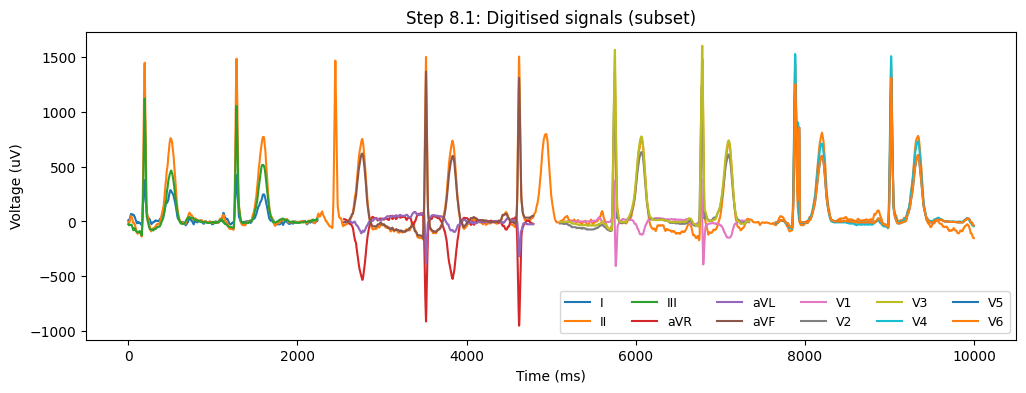

Saved: digitised_ecg.csv  (5000 rows x 12 cols)
Saved: digitised_ecg.npz


In [ ]:
# -----------------------------
# Step 8: Convert recovered traces to canonical format
# -----------------------------

debug_lead = ""

if debug_lead in lead_results:
    show_lead_result(debug_lead, debug=True)

# ─────────────────────────────────────────────
# Step 8: Convert recovered traces to canonical format
# 5000 rows, 2ms interval, µV, time-aligned by lead group
# ─────────────────────────────────────────────
lead_order = ["I","II","III","aVR","aVL","aVF","V1","V2","V3","V4","V5","V6"]

# Time offset per lead group matching standard 3x4 ECG layout.
# Kept as metadata/reference, but short leads are placed on the canonical
# timeline using their actual crop x-position within the sheet.
lead_offset_ms = {
    "I":   0,    "II":   0,    "III":   0,    # Column 1: 0–2.5 s
    "aVR": 2500, "aVL": 2500,  "aVF": 2500,   # Column 2: 2.5–5 s
    "V1":  5000, "V2":  5000,  "V3":  5000,   # Column 3: 5–7.5 s
    "V4":  7500, "V5":  7500,  "V6":  7500,   # Column 4: 7.5–10 s
}

# Lead II comes from the rhythm strip (full 10 s), not the short crop
exclude_from_12lead = {"II"}

CANONICAL_ROWS = 5000
DT_MS = float(P["interp_dt_ms"])   # 2.0 ms
t_canonical = np.arange(CANONICAL_ROWS, dtype=np.float32) * DT_MS

ref_w = rhythm.shape[1] if rhythm is not None else max(
    v.crop_binary.shape[1] for v in lead_results.values())
time_res_ms = (P["time_seconds_total"] * 1000.0) / ref_w
volt_res_mV = time_res_ms * P["voltage_time_ratio_mV_per_ms"]

# Use the left edge of the full-width strip region as the global time origin
# so short-lead crops and the rhythm strip share the same horizontal reference.
paper_x0 = left + lr_pad

print(f"Calibration: ref_w={ref_w}px => {time_res_ms:.4f} ms/px, {volt_res_mV:.6f} mV/px")

lead_signals = {}

# --- 12 short leads (excluding II which comes from the rhythm strip) ---
for lead in lead_order:
    if lead in exclude_from_12lead:
        continue

    lead_result = lead_results.get(lead)
    if lead_result is None or lead_result.y_trace is None:
        continue

    y = lead_result.y_trace
    valid = ~np.isnan(y)
    if valid.sum() < 20:
        continue

    y0 = np.nanmedian(y[valid])
    amp_px = y0 - y
    amp_mV = amp_px * volt_res_mV

    # Place the crop on the shared 10 s axis using its true global x-position.
    crop_x0 = int(lead_result.crop_box[0])
    t_global = ((crop_x0 - paper_x0) + np.arange(len(amp_mV), dtype=np.float32)) * time_res_ms

    # Interpolate onto canonical grid; NaN outside the crop's true time support.
    v_mV = np.interp(t_canonical, t_global[valid], amp_mV[valid],
                     left=np.nan, right=np.nan)

    lead_signals[lead] = v_mV * 1000.0   # mV → µV

# --- Rhythm strip → Lead II (full 10 s) ---
if rhythm is not None:
    y_rhythm, rhythm_debug = extract_trace_local(
        rhythm, dilate_k=int(P["dilate_k"]), lead=None, params=P
    )

    if y_rhythm is not None:
        valid = ~np.isnan(y_rhythm)
        if valid.sum() >= 20:
            y0_r = np.nanmedian(y_rhythm[valid])
            amp_px_r = y0_r - y_rhythm
            amp_mV_r = amp_px_r * volt_res_mV

            t_local_r = np.arange(len(amp_mV_r), dtype=np.float32) * time_res_ms
            # Rhythm strip covers 0 → 10 s with no offset
            v_mV_r = np.interp(
                t_canonical,
                t_local_r[valid],
                amp_mV_r[valid],
                left=np.nan,
                right=np.nan,
            )
            lead_signals["II"] = v_mV_r * 1000.0   # mV → µV
            print("Rhythm strip integrated into Lead II.")
        else:
            print("WARNING: rhythm strip trace has too few valid samples; Lead II will be NaN.")
    else:
        print("WARNING: rhythm strip trace extraction failed; Lead II will be NaN.")
else:
    print("WARNING: no rhythm strip crop found; Lead II will be NaN.")

print("Extracted leads:", sorted(lead_signals.keys()))

plt.figure(figsize=(12,4))
for lead in lead_order:
    if lead in lead_signals:
        plt.plot(t_canonical, lead_signals[lead], label=lead)
plt.title("Step 8.1: Digitised signals (subset)")
plt.xlabel("Time (ms)")
plt.ylabel("Voltage (uV)")
plt.legend(ncol=6, fontsize=9)
plt.show()

# Build output: 5000 rows × 12 columns, no time column
out_csv = "../archive/digitised_ecg.csv"
cols = []
for lead in lead_order:
    if lead in lead_signals:
        cols.append(lead_signals[lead])
    else:
        cols.append(np.full(CANONICAL_ROWS, np.nan, dtype=np.float32))

mat = np.column_stack(cols)
assert mat.shape == (CANONICAL_ROWS, len(lead_order)), f"Shape mismatch: {mat.shape}"

# Build canonical binary masks aligned to the exported signal matrix.
def _paint_canonical_overlap_mask(cluster_counts, t_centers_ms, signal_vec_uV):
    mask = np.zeros(CANONICAL_ROWS, dtype=np.uint8)
    if cluster_counts is None:
        return mask
    cluster_counts = np.asarray(cluster_counts)
    overlap_cols = np.where(cluster_counts >= 2)[0]
    if overlap_cols.size == 0:
        return mask
    half_px_ms = 0.5 * time_res_ms
    for x_coord in overlap_cols:
        t0 = max(0.0, float(t_centers_ms[x_coord] - half_px_ms))
        t1 = min(float(t_canonical[-1] + DT_MS), float(t_centers_ms[x_coord] + half_px_ms))
        i0 = max(0, int(np.floor(t0 / DT_MS)))
        i1 = min(CANONICAL_ROWS, int(np.ceil(t1 / DT_MS)))
        mask[i0:i1] = 1
    if signal_vec_uV is not None:
        mask = (mask & (~np.isnan(signal_vec_uV)).astype(np.uint8)).astype(np.uint8)
    return mask


def _paint_canonical_interpolated_mask(interpolation_cols, t_centers_ms, signal_vec_uV):
    mask = np.zeros(CANONICAL_ROWS, dtype=np.uint8)
    if interpolation_cols is None:
        return mask
    interpolation_cols = np.asarray(interpolation_cols)
    active_cols = np.where(interpolation_cols > 0)[0]
    if active_cols.size == 0:
        return mask
    half_px_ms = 0.5 * time_res_ms
    for x_coord in active_cols:
        t0 = max(0.0, float(t_centers_ms[x_coord] - half_px_ms))
        t1 = min(float(t_canonical[-1] + DT_MS), float(t_centers_ms[x_coord] + half_px_ms))
        i0 = max(0, int(np.floor(t0 / DT_MS)))
        i1 = min(CANONICAL_ROWS, int(np.ceil(t1 / DT_MS)))
        mask[i0:i1] = 1
    if signal_vec_uV is not None:
        mask = (mask & (~np.isnan(signal_vec_uV)).astype(np.uint8)).astype(np.uint8)
    return mask

canonical_overlap_cols = []
for lead in lead_order:
    signal_vec = lead_signals.get(lead, np.full(CANONICAL_ROWS, np.nan, dtype=np.float32))
    if lead == "II":
        cluster_counts = None if rhythm_overlap_result is None else rhythm_overlap_result.get("cluster_counts")
        is_overlapping = bool(rhythm_overlap_result is not None and rhythm_overlap_result.get("is_overlapping", False))
        t_centers_ms = np.arange(len(cluster_counts), dtype=np.float32) * time_res_ms if cluster_counts is not None else None
        mask = _paint_canonical_overlap_mask(cluster_counts, t_centers_ms, signal_vec) if (is_overlapping and t_centers_ms is not None) else np.zeros(CANONICAL_ROWS, dtype=np.uint8)
    else:
        lead_result = lead_results.get(lead)
        lead_overlap_info = overlap_results.get(lead)
        cluster_counts = None if lead_overlap_info is None else lead_overlap_info.get("cluster_counts")
        is_overlapping = bool(lead_overlap_info is not None and lead_overlap_info.get("is_overlapping", False))
        if lead_result is not None and cluster_counts is not None and is_overlapping:
            crop_x0 = int(lead_result.crop_box[0])
            t_centers_ms = ((crop_x0 - paper_x0) + np.arange(len(cluster_counts), dtype=np.float32)) * time_res_ms
            mask = _paint_canonical_overlap_mask(cluster_counts, t_centers_ms, signal_vec)
        else:
            mask = np.zeros(CANONICAL_ROWS, dtype=np.uint8)
    canonical_overlap_cols.append(mask)

overlap_mask = np.column_stack(canonical_overlap_cols).astype(np.uint8)
assert overlap_mask.shape == mat.shape, f"Overlap-mask shape mismatch: {overlap_mask.shape} vs {mat.shape}"

canonical_interpolated_cols = []
for lead in lead_order:
    signal_vec = lead_signals.get(lead, np.full(CANONICAL_ROWS, np.nan, dtype=np.float32))
    if lead == "II":
        interpolation_cols = None if rhythm_debug is None else rhythm_debug.get("interpolation_mask")
        t_centers_ms = np.arange(len(interpolation_cols), dtype=np.float32) * time_res_ms if interpolation_cols is not None else None
        mask = _paint_canonical_interpolated_mask(interpolation_cols, t_centers_ms, signal_vec) if t_centers_ms is not None else np.zeros(CANONICAL_ROWS, dtype=np.uint8)
    else:
        lead_result = lead_results.get(lead)
        interpolation_cols = None if lead_result is None else lead_result.interpolation_mask
        if lead_result is not None and interpolation_cols is not None:
            crop_x0 = int(lead_result.crop_box[0])
            t_centers_ms = ((crop_x0 - paper_x0) + np.arange(len(interpolation_cols), dtype=np.float32)) * time_res_ms
            mask = _paint_canonical_interpolated_mask(interpolation_cols, t_centers_ms, signal_vec)
        else:
            mask = np.zeros(CANONICAL_ROWS, dtype=np.uint8)
    canonical_interpolated_cols.append(mask)

interpolated_mask = np.column_stack(canonical_interpolated_cols).astype(np.uint8)
assert interpolated_mask.shape == mat.shape, f"Interpolated-mask shape mismatch: {interpolated_mask.shape} vs {mat.shape}"

np.savetxt(out_csv, mat, delimiter=",", header=",".join(lead_order), comments="")
print(f"Saved: {out_csv}  ({mat.shape[0]} rows x {mat.shape[1]} cols)")

short_lead_overlap_results = {
    k: {kk: vv for kk, vv in v.items() if kk != "cluster_counts"}
    for k, v in overlap_results.items()
}
rhythm_strip_overlap_result = (
    {k: v for k, v in rhythm_overlap_result.items() if k != "cluster_counts"}
    if rhythm_overlap_result is not None else None
)

# Also save npz
out_npz = "../archive/digitised_ecg.npz"
np.savez_compressed(
    out_npz,
    **{k: v for k, v in lead_signals.items()},
    signal_matrix=mat,
    overlap_mask=overlap_mask,
    interpolated_mask=interpolated_mask,
    lead_order=np.array(lead_order, dtype="<U4"),
    t_ms=t_canonical,
    meta=json.dumps({
        "params": P,
        "time_res_ms_per_px": time_res_ms,
        "volt_res_mV_per_px": volt_res_mV,
        "image_path": IMG_PATH,
        "canonical_rows": CANONICAL_ROWS,
        "dt_ms": DT_MS,
        "units": "uV",
        "lead_order": lead_order,
        "lead_offset_ms": lead_offset_ms,
        "alignment_mode": "global_crop_x",
        "paper_x0_px": int(paper_x0),
        "excluded_from_12lead": list(exclude_from_12lead),
        "overlap_detection_mode": "vertical_close_column_count",
        "overlap_vertical_close_h": int(P["overlap_vertical_close_h"]),
        "overlap_column_count_threshold": int(P["overlap_column_count_threshold"]),
        "short_lead_overlap_results": short_lead_overlap_results,
        "rhythm_strip_overlap_result": rhythm_strip_overlap_result,
        "overlap_mask_array": "overlap_mask",
        "overlap_mask_description": "5000x12 canonical binary mask aligned to signal_matrix and lead_order, but only for leads marked overlapping by the main thresholded decision",
        "interpolated_mask_array": "interpolated_mask",
        "interpolated_mask_description": "5000x12 canonical binary mask aligned to signal_matrix and lead_order, marking only samples inferred by interpolation in top-row leads and the rhythm strip export",
        "exported_lead_ii_overlap_source": "rhythm_strip_overlap_result",
        "exported_lead_ii_interpolation_source": "rhythm_strip",
    })
)
print("Saved:", out_npz)


=== Overlap Detection (vertical close + fixed column threshold) ===
     I: ✓ clean  (0/648 cols, close_h=7, cols>3; legacy_ratio=0.0%)
   III: ✓ clean  (0/648 cols, close_h=7, cols>3; legacy_ratio=0.5%)
   aVR: ✓ clean  (0/648 cols, close_h=7, cols>3; legacy_ratio=0.0%)
   aVL: ✓ clean  (0/648 cols, close_h=7, cols>3; legacy_ratio=0.2%)
   aVF: ✓ clean  (0/648 cols, close_h=7, cols>3; legacy_ratio=0.2%)
    V1: ✓ clean  (0/648 cols, close_h=7, cols>3; legacy_ratio=0.2%)
    V2: ✓ clean  (0/648 cols, close_h=7, cols>3; legacy_ratio=0.6%)
    V3: ✓ clean  (0/648 cols, close_h=7, cols>3; legacy_ratio=0.8%)
    V4: ⚠ OVERLAP  (12/678 cols, close_h=7, cols>3; legacy_ratio=1.9%)
    V5: ⚠ OVERLAP  (13/678 cols, close_h=7, cols>3; legacy_ratio=2.2%)
    V6: ⚠ OVERLAP  (13/678 cols, close_h=7, cols>3; legacy_ratio=2.2%)
  II(rhythm): ✓ clean  (2/2892 cols, close_h=7, cols>3; legacy_ratio=0.4%)


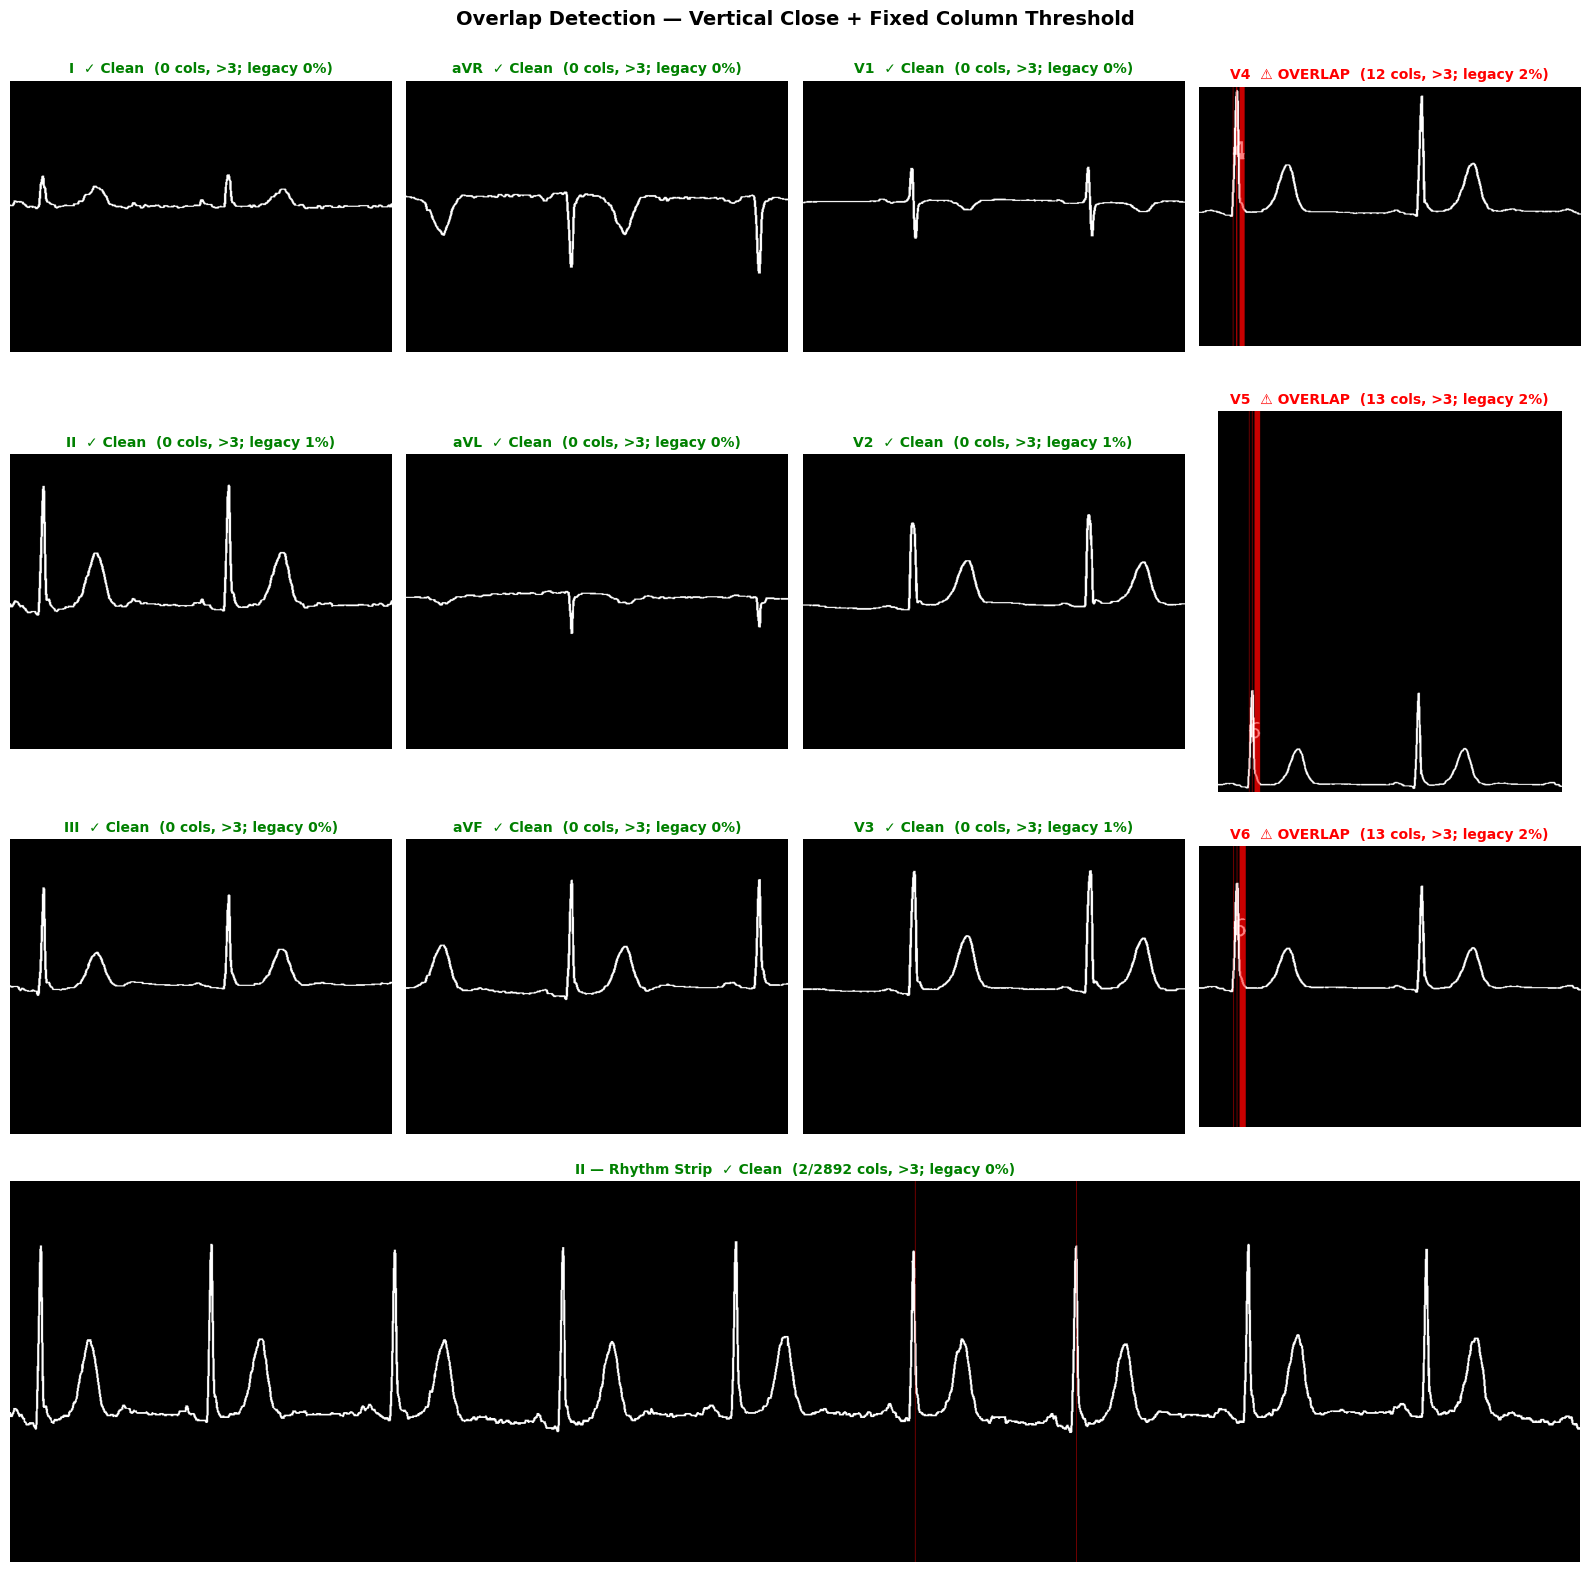

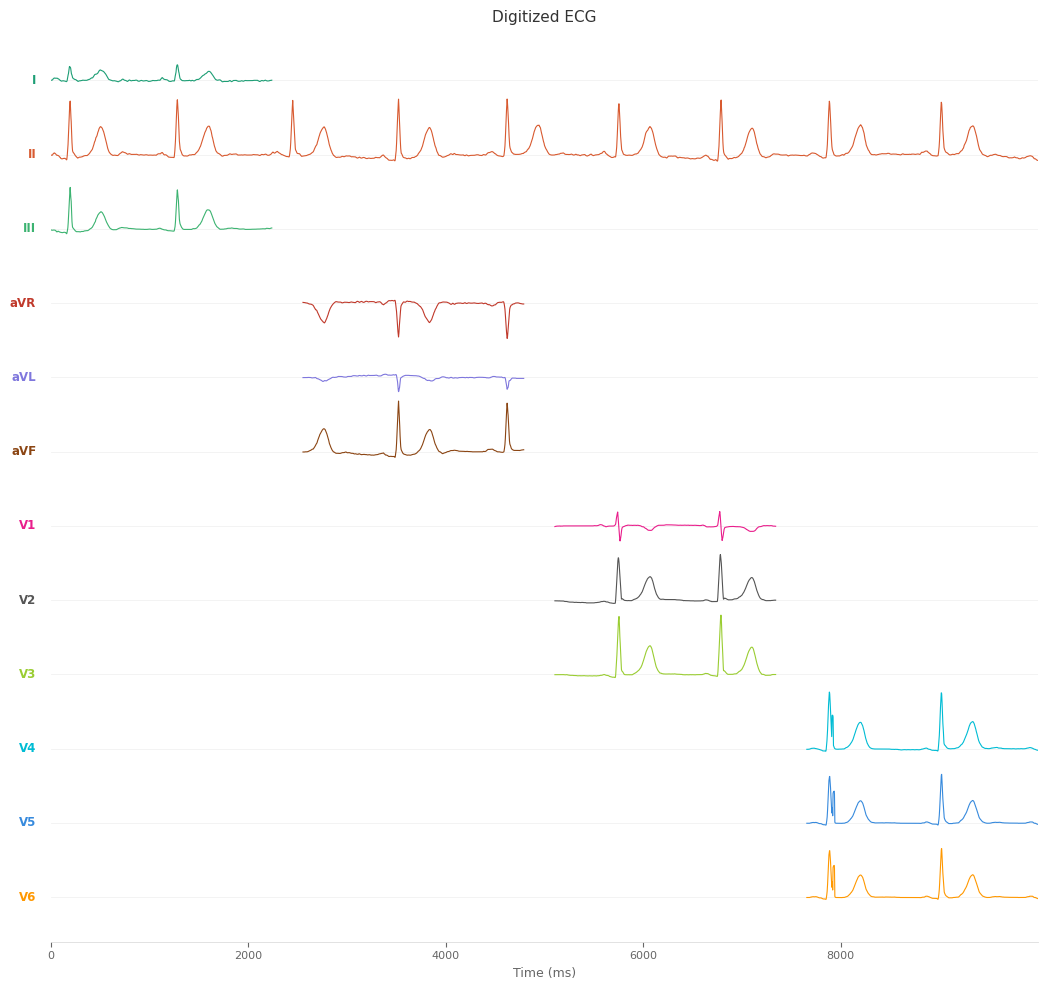

In [ ]:
# ─────────────────────────────────────────────
# Visualization
# ─────────────────────────────────────────────

# --- Re-run overlap detection so this block is self-contained ---
frame_top_y_for_overlap = globals().get("frame_top_y", None)
legacy_overlap_results = {}
overlap_results = {}
overlap_debug_results = {}
for lead, lr in lead_results.items():
    legacy_overlap_results[lead] = detect_overlap_in_mask(
        lr.connected_mask,
        overlap_ratio_threshold=float(P["overlap_ratio_threshold"]),
    )
    overlap_results[lead], overlap_debug_results[lead] = detect_overlap_with_vertical_close_local(
        lr.crop_binary,
        lead=lead,
        params=P,
        crop_y0=int(lr.crop_box[1]),
        frame_top_y=frame_top_y_for_overlap,
        overlap_ratio_threshold=float(P["overlap_ratio_threshold"]),
        anomaly_column_threshold=int(P["overlap_column_count_threshold"]),
    )

# Rhythm strip overlap (legacy ratio retained for reference only)
legacy_rhythm_overlap_result = None
rhythm_overlap_result = None
rhythm_overlap_debug = None
if rhythm is not None:
    _, rhythm_debug_viz = extract_trace_local(
        rhythm, dilate_k=int(P["dilate_k"]), lead=None, params=P
    )
    rhythm_mask_viz = rhythm_debug_viz["mask"]
    if rhythm_mask_viz.size > 0:
        legacy_rhythm_overlap_result = detect_overlap_in_mask(
            rhythm_mask_viz,
            overlap_ratio_threshold=float(P["rhythm_overlap_ratio_threshold"]),
        )
    rhythm_overlap_result, rhythm_overlap_debug = detect_overlap_with_vertical_close_local(
        rhythm,
        lead=None,
        params=P,
        overlap_ratio_threshold=float(P["rhythm_overlap_ratio_threshold"]),
        anomaly_column_threshold=int(P["overlap_column_count_threshold"]),
    )

# --- Print summary ---
print("=== Overlap Detection (vertical close + fixed column threshold) ===")
for lead in ["I", "III", "aVR", "aVL", "aVF", "V1", "V2", "V3", "V4", "V5", "V6"]:
    if lead not in overlap_results:
        continue
    info = overlap_results[lead]
    legacy = legacy_overlap_results[lead]
    tag = "⚠ OVERLAP" if info["is_overlapping"] else "✓ clean"
    print(
        f"  {lead:>4s}: {tag}  "
        f"({info['overlap_columns']}/{info['total_columns']} cols, "
        f"close_h={P['overlap_vertical_close_h']}, cols>{P['overlap_column_count_threshold']}; "
        f"legacy_ratio={legacy['overlap_ratio']:.1%})"
    )

if rhythm_overlap_result is not None:
    info = rhythm_overlap_result
    legacy = legacy_rhythm_overlap_result
    tag = "⚠ OVERLAP" if info["is_overlapping"] else "✓ clean"
    legacy_text = f"{legacy['overlap_ratio']:.1%}" if legacy is not None else "n/a"
    print(
        f"  {'II(rhythm)':>10s}: {tag}  "
        f"({info['overlap_columns']}/{info['total_columns']} cols, "
        f"close_h={P['overlap_vertical_close_h']}, cols>{P['overlap_column_count_threshold']}; "
        f"legacy_ratio={legacy_text})"
    )

# --- Helper: paint overlap columns red in a grayscale mask ---
def _paint_overlap_columns(mask_gray, cluster_counts):
    """Return an RGB image with overlapping columns tinted red."""
    overlay = cv2.cvtColor(mask_gray, cv2.COLOR_GRAY2RGB)
    w = min(len(cluster_counts), overlay.shape[1])
    for x in range(w):
        if cluster_counts[x] >= 2:
            overlay[:, x, 0] = np.maximum(overlay[:, x, 0], 200)
            overlay[:, x, 1] = overlay[:, x, 1] // 2
            overlay[:, x, 2] = overlay[:, x, 2] // 2
    return overlay

# --- Grid figure: 3×4 lead grid + 1 rhythm strip row ---
has_rhythm = rhythm_overlap_result is not None and rhythm is not None and rhythm_overlap_debug is not None

# 4 rows if we have a rhythm strip, else 3
n_rows = 4 if has_rhythm else 3
fig = plt.figure(figsize=(16, 4 * n_rows))
fig.suptitle("Overlap Detection — Vertical Close + Fixed Column Threshold", fontsize=14, fontweight="bold")

# --- 3×4 short-lead grid ---
for r in range(3):
    for c in range(4):
        lead = layout[r][c]
        ax = fig.add_subplot(n_rows, 4, r * 4 + c + 1)
        ax.axis("off")

        if lead not in lead_results or lead not in overlap_results:
            ax.set_title(lead, color="gray", fontsize=10)
            continue

        info = overlap_results[lead]
        legacy = legacy_overlap_results[lead]
        overlay = _paint_overlap_columns(
            overlap_debug_results[lead]["mask"], info["cluster_counts"]
        )
        ax.imshow(overlay)

        color = "red" if info["is_overlapping"] else "green"
        label = (
            f"{lead}  {'⚠ OVERLAP' if info['is_overlapping'] else '✓ Clean'}"
            f"  ({info['overlap_columns']} cols, >{P['overlap_column_count_threshold']}; "
            f"legacy {legacy['overlap_ratio']:.0%})"
        )
        ax.set_title(label, color=color, fontsize=10, fontweight="bold")

# --- Rhythm strip row (spans all 4 columns) ---
if has_rhythm:
    ax_rhythm = fig.add_subplot(n_rows, 1, n_rows)   # full-width bottom row
    ax_rhythm.axis("off")

    info = rhythm_overlap_result
    legacy = legacy_rhythm_overlap_result
    overlay_r = _paint_overlap_columns(rhythm_overlap_debug["mask"], info["cluster_counts"])
    ax_rhythm.imshow(overlay_r, aspect="auto")

    color = "red" if info["is_overlapping"] else "green"
    legacy_text = f"{legacy['overlap_ratio']:.0%}" if legacy is not None else "n/a"
    label = (
        f"II — Rhythm Strip  {'⚠ OVERLAP' if info['is_overlapping'] else '✓ Clean'}"
        f"  ({info['overlap_columns']}/{info['total_columns']} cols, >{P['overlap_column_count_threshold']}; "
        f"legacy {legacy_text})"
    )
    ax_rhythm.set_title(label, color=color, fontsize=10, fontweight="bold")

plt.tight_layout()
plt.show()

LEAD_ORDER = ["I","II","III","aVR","aVL","aVF","V1","V2","V3","V4","V5","V6"]
LEAD_COLOR = {
    "I":"#1D9E75","II":"#D85A30","III":"#3CB371",
    "aVR":"#C0392B","aVL":"#7F77DD","aVF":"#8B4513",
    "V1":"#E91E8C","V2":"#555555","V3":"#9ACD32",
    "V4":"#00BCD4","V5":"#378ADD","V6":"#FF9800",
}

def plot_ecg_stacked(lead_signals, t_ms=None, spacing_uV=2000, title="Digitized ECG", save_path=None):
    present = [l for l in LEAD_ORDER if l in lead_signals]
    n = len(present)
    ref_len = max(len(lead_signals[l]) for l in present)
    t = np.asarray(t_ms, dtype=np.float32) if t_ms is not None and len(t_ms) == ref_len else np.arange(ref_len, dtype=np.float32)

    fig, ax = plt.subplots(figsize=(11, 10), facecolor="white")
    ax.set_facecolor("white")

    for rank, lead in enumerate(present):
        sig = np.asarray(lead_signals[lead], dtype=np.float32)
        sig = sig - np.nanmedian(sig[~np.isnan(sig)])
        offset = (n - 1 - rank) * spacing_uV
        ax.plot(t[:len(sig)], sig[:ref_len] + offset, color=LEAD_COLOR[lead], linewidth=0.8, rasterized=True)
        ax.text(t[0] - (t[-1] - t[0]) * 0.015, offset, lead, fontsize=8.5, fontweight="bold",
                color=LEAD_COLOR[lead], va="center", ha="right", clip_on=False)
        ax.axhline(offset, color="#eeeeee", linewidth=0.5, zorder=1)

    ax.set_yticks([])
    ax.set_xlim(t[0], t[-1])
    ax.set_ylim(-spacing_uV * 0.6, (n - 1) * spacing_uV + spacing_uV * 0.6)
    ax.set_xlabel("Time (ms)" if t_ms is not None else "Sample index", fontsize=9, color="#666")
    ax.tick_params(axis="x", labelsize=8, colors="#666")
    for sp in ["top", "right", "left"]: ax.spines[sp].set_visible(False)
    ax.spines["bottom"].set_edgecolor("#dddddd"); ax.spines["bottom"].set_linewidth(0.6)
    ax.set_title(title, fontsize=11, color="#333", pad=10)
    fig.tight_layout(rect=[0.04, 0, 1, 1])

    if save_path:
        fig.savefig(save_path, dpi=180, bbox_inches="tight", facecolor="white")
    plt.show()
    plt.close(fig)

plot_ecg_stacked(
    lead_signals=lead_signals,  # dict already built by the pipeline (µV)
    t_ms=t_canonical,           # the 5000-point ms axis
)

In [ ]:
# -----------------------------
# NPZ Raw Data Preview
# -----------------------------

preview_npz_path = globals().get("out_npz", "../archive/digitised_ecg.npz")
npz_obj = np.load(preview_npz_path, allow_pickle=True)

print("NPZ path:", preview_npz_path)
print("Stored keys:", list(npz_obj.files))
print()

for key in npz_obj.files:
    arr = npz_obj[key]
    if key == "meta":
        meta = json.loads(str(arr))
        print(f"[{key}] JSON metadata with {len(meta)} top-level keys")
        print("  keys:", sorted(meta.keys()))
        continue
    print(f"[{key}] shape={arr.shape}, dtype={arr.dtype}")
print()

meta = json.loads(str(npz_obj["meta"]))
print("Metadata preview:")
for meta_key in [
    "image_path",
    "units",
    "alignment_mode",
    "overlap_detection_mode",
    "overlap_vertical_close_h",
    "overlap_column_count_threshold",
    "interpolated_mask_array",
]:
    if meta_key in meta:
        print(f"  {meta_key}: {meta[meta_key]}")
print()

signal_matrix_preview = npz_obj["signal_matrix"][:8, :4]
overlap_mask_preview = npz_obj["overlap_mask"][:20, :4]
interpolated_mask_preview = npz_obj["interpolated_mask"][:20, :4]

with np.printoptions(precision=2, suppress=True, linewidth=140):
    print("signal_matrix[:8, :4] -> columns", npz_obj["lead_order"][:4].tolist())
    print(signal_matrix_preview)
    print()
    print("overlap_mask[:20, :4]")
    print(overlap_mask_preview)
    print()
    print("interpolated_mask[:20, :4]")
    print(interpolated_mask_preview)

npz_obj.close()

NPZ path: digitised_ecg.npz
Stored keys: ['I', 'III', 'aVR', 'aVL', 'aVF', 'V1', 'V2', 'V3', 'V4', 'V5', 'V6', 'II', 'signal_matrix', 'overlap_mask', 'interpolated_mask', 'lead_order', 't_ms', 'meta']

[I] shape=(5000,), dtype=float64
[III] shape=(5000,), dtype=float64
[aVR] shape=(5000,), dtype=float64
[aVL] shape=(5000,), dtype=float64
[aVF] shape=(5000,), dtype=float64
[V1] shape=(5000,), dtype=float64
[V2] shape=(5000,), dtype=float64
[V3] shape=(5000,), dtype=float64
[V4] shape=(5000,), dtype=float64
[V5] shape=(5000,), dtype=float64
[V6] shape=(5000,), dtype=float64
[II] shape=(5000,), dtype=float64
[signal_matrix] shape=(5000, 12), dtype=float64
[overlap_mask] shape=(5000, 12), dtype=uint8
[interpolated_mask] shape=(5000, 12), dtype=uint8
[lead_order] shape=(12,), dtype=<U4
[t_ms] shape=(5000,), dtype=float32
[meta] JSON metadata with 23 top-level keys
  keys: ['alignment_mode', 'canonical_rows', 'dt_ms', 'excluded_from_12lead', 'exported_lead_ii_interpolation_source', 'exported